# Project Phase 2 — Statistical Damage Detection

**Course:** CIV E 789 Sensing Techniques and Data Analytics (Fall 2026)  
**Instructor:** Mohammad Talebi-Kalaleh, Ph.D.  
**Group:** 6 (sensors S2, S4, S6, S9, S12, S15, S18, S21, S24)  
**Data:** `phase2_modal_parameters.json` (intact, damage1, damage2; 20 estimates each)

## Contents

0. [Setup](#setup)
1. [Part A: Feature Distribution Analysis](#part-a)
2. [Part B: Single Feature Damage Detection](#part-b)
3. [Part C: Bivariate Analysis](#part-c)
4. [Part D: Feature Fusion and Engineering](#part-d)
5. [Part E: Principal Component Analysis](#part-e)
6. [Part F: Engineering Insights](#part-f)
7. [Use of Generative AI](#ai-note)

<a id="setup"></a>
## 0. Setup

This section loads the data used throughout the project and sets up the common tools. Parts A–E start from the arrays created here, so that all of them work with exactly the same data.

- **0.1** Libraries, paths and helper functions to present tables and figures.
- **0.2** Loading the JSON file and the group 6 sensors.
- **0.3** Extraction of natural frequencies and mode shapes, with automatic checks.

In [1]:
# Google Colab only: mount Google Drive and run from the project folder (does nothing elsewhere)
import os
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')

    # Find the project folder wherever it is in the Drive: usual locations first, then a full search
    DRIVE_ROOT = Path('/content/drive')
    PROJECT = 'ProjectPhase2_Group6'
    usual = [f'MyDrive/CIV E 789/{PROJECT}', f'MyDrive/{PROJECT}', f'Shareddrives/*/CIV E 789/{PROJECT}',
             f'.shortcut-targets-by-id/*/CIV E 789/{PROJECT}']
    found = [p for pattern in usual for p in DRIVE_ROOT.glob(pattern)
             if (p / 'phase2_modal_parameters.json').exists()]
    if not found:
        found = [p.parent for p in DRIVE_ROOT.glob(f'**/{PROJECT}/phase2_modal_parameters.json')]
    assert found, f'{PROJECT} folder with phase2_modal_parameters.json not found in Google Drive'
    os.chdir(found[0])
    print('Working folder:', found[0])

In [2]:
# Google Colab only: mount Google Drive and run from the project folder
import os
import sys
from pathlib import Path

if 'google.colab' in sys.modules:
    from google.colab import drive
    drive.mount('/content/drive')

    # Using the exact path you located
    PROJECT_DIR = Path('/content/drive/MyDrive/Colab Notebooks/CIV E 789/ProjectPhase2_Group6')

    # Verify the file is exactly where we expect it
    assert (PROJECT_DIR / 'phase2_modal_parameters.json').exists(), f'File not found in {PROJECT_DIR}'

    # Change the working directory to your project folder
    os.chdir(PROJECT_DIR)
    print('Working folder:', os.getcwd())

### 0.1 Libraries, paths and presentation helpers

- The file `phase2_modal_parameters.json` is searched for first in the notebook folder and, if it is not there, in the parent folder.
- Figures are saved in `figures/part-a/` … `figures/part-e/` and result tables in `results/` (CSV). The folders are created if they do not exist.
- `show_table` places the table caption above the table (**Table N.**) and `show_figure` places the figure caption below the figure (**Figure N.**), both outside the object. `show_figure` also saves the figure in the folder of its part.

In [3]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Input data: next to this notebook or, if not there, in the parent folder
DATA_FILE = 'phase2_modal_parameters.json'
DATA_PATH = next((p for p in (Path(DATA_FILE), Path('..') / DATA_FILE) if p.exists()), None)
assert DATA_PATH is not None, f'{DATA_FILE} not found next to the notebook or in its parent folder'

# Output folders: one figure folder per part, one folder for result tables
FIG_DIR = Path('figures')
RES_DIR = Path('results')
for part in ['part-a', 'part-b', 'part-c', 'part-d', 'part-e']:
    (FIG_DIR / part).mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(exist_ok=True)


def show_table(df, number, caption, filename=None, precision=4):
    """Show the table caption above the table; optionally save the table as CSV in results/."""
    display(Markdown(f'**Table {number}.** {caption}'))
    display(df.style.format(precision=precision))
    if filename is not None:
        df.to_csv(RES_DIR / filename)


def show_figure(fig, number, caption, part, filename):
    """Save the figure in figures/<part>/, show it and put the caption below it."""
    fig.savefig(FIG_DIR / part / filename, dpi=300, bbox_inches='tight')
    display(fig)
    plt.close(fig)
    display(Markdown(f'**Figure {number}.** {caption}'))

### 0.2 Data loading and group 6 sensors

- The JSON file has two blocks: `scenarios` (data for `intact`, `damage1` and `damage2`) and `metadata` (sampling information, sensors assigned to each group and position of each sensor).
- The group sensors are read from `metadata.sensor_assignments.group_6` instead of being typed by hand, to avoid copying errors.
- Each mode shape is a list of 24 values ordered from S1 to S24, so sensor $S_k$ is at index $k-1$ of the list (Table 1).
- The position of each sensor (`metadata.sensor_positions_m`) will be used as the x-axis of the mode shapes.

In [4]:
with open(DATA_PATH, 'r') as f:
    data = json.load(f)

GROUP = 6
SCENARIOS = ['intact', 'damage1', 'damage2']
MODES = ['mode_1', 'mode_2', 'mode_3']
N_MEAS = data['metadata']['sampling_info']['total_estimates']   # 20 estimates per condition
N_SENSORS_TOTAL = len(data['metadata']['sensor_positions_m'])   # 24 sensors on the bridge

# Sensors assigned to our group, read from the file (not typed by hand)
my_sensors = data['metadata']['sensor_assignments'][f'group_{GROUP}']
SENSOR_IDX = np.array([int(s[1:]) - 1 for s in my_sensors])   # Sk -> list index k - 1
SENSOR_POS = np.array([data['metadata']['sensor_positions_m'][s] for s in my_sensors])   # [m]

sensors_table = pd.DataFrame({'List index': SENSOR_IDX, 'Position (m)': SENSOR_POS},
                             index=pd.Index(my_sensors, name='Sensor'))
show_table(sensors_table, 1, f'Sensors assigned to group {GROUP}, their index in the 24-value lists '
           'and their position along the bridge.', precision=1)

**Table 1.** Sensors assigned to group 6, their index in the 24-value lists and their position along the bridge.

,List index,Position (m)
Sensor,,
S2,1,7.5
S4,3,17.5
S6,5,27.5
S9,8,42.5
S12,11,57.5
S15,14,72.5
S18,17,87.5
S21,20,102.5
S24,23,117.5


### 0.3 Extraction of natural frequencies and mode shapes

The first cell defines the two extraction functions from the assignment starter code (Section 7), with the same names and behaviour: `extract_frequencies(scenario, mode_key)` returns the 20 frequencies of one mode, and `extract_mode_shape(scenario, measurement_idx, mode_key)` returns one mode shape at the 9 group sensors. The second cell uses them to store the data in numpy arrays, one per scenario (Table 2).

**Table 2.** Numpy arrays created in the data extraction.

| Array | Size | Content |
|---|---|---|
| `freqs[scenario]` | 20 × 3 | measurements × modes, natural frequency in Hz |
| `shapes[scenario]` | 3 × 20 × 9 | modes × measurements × group 6 sensors |

- **Assumption:** value $i$ of each frequency list and `measurement_i` of the mode shapes come from the same 30-s segment. The assignment does not state this explicitly. It does not matter for Parts A and B, which analyse each feature separately, but Parts C, D and E combine several features of the same measurement into a single point.
- Measurements are read as `measurement_1` … `measurement_20` in numeric order, not in the order of the JSON keys.
- Mode shapes are not normalized again: they are already scaled to a maximum of 1 over the 24 sensors. The MAC does not depend on scale, so this does not affect it.
- The checks (`assert`) stop the notebook if a measurement is missing, if a mode shape does not have 24 values, or if there are missing values (NaN).

In [5]:
# Extraction functions from the starter code (same names and behaviour)

# Extract frequencies for a scenario
def extract_frequencies(scenario, mode_key='mode_1'):
    return np.array(data['scenarios'][scenario]['natural_frequencies'][mode_key])


# Extract mode shape at assigned sensors
def extract_mode_shape(scenario, measurement_idx, mode_key='mode_1'):
    mode_data = data['scenarios'][scenario]['mode_shapes'][mode_key][f'measurement_{measurement_idx}']
    # mode_data is a list of 24 values ordered S1..S24, so S1 -> index 0
    return np.array([mode_data[int(s[1:]) - 1] for s in my_sensors])

In [6]:
# freqs[scenario]:  (N_MEAS, 3) array -> measurements x modes, in Hz
# shapes[scenario]: (3, N_MEAS, 9) array -> modes x measurements x our 9 sensors
# Measurements are read as measurement_1 ... measurement_20 (numeric order), so row i of
# freqs and measurement i of shapes refer to the same 30-s segment.
freqs = {}
shapes = {}
for sc in SCENARIOS:
    freqs[sc] = np.column_stack([extract_frequencies(sc, m) for m in MODES])
    shapes[sc] = np.array([[extract_mode_shape(sc, i, m) for i in range(1, N_MEAS + 1)]
                           for m in MODES])

# Sanity checks on the raw file and on the extracted arrays
for sc in SCENARIOS:
    for m in MODES:
        assert len(data['scenarios'][sc]['natural_frequencies'][m]) == N_MEAS
        mode_shapes = data['scenarios'][sc]['mode_shapes'][m]
        assert set(mode_shapes) == {f'measurement_{i}' for i in range(1, N_MEAS + 1)}
        assert all(len(v) == N_SENSORS_TOTAL for v in mode_shapes.values())
    assert freqs[sc].shape == (N_MEAS, len(MODES))
    assert shapes[sc].shape == (len(MODES), N_MEAS, len(my_sensors))
    assert np.isfinite(freqs[sc]).all() and np.isfinite(shapes[sc]).all()
print('Extraction checks passed: '
      f'{len(SCENARIOS)} scenarios x {len(MODES)} modes x {N_MEAS} measurements x {len(my_sensors)} sensors')

Extraction checks passed: 3 scenarios x 3 modes x 20 measurements x 9 sensors


In [7]:
# One table per scenario: rows = modes, columns = measurements
for t, sc in enumerate(SCENARIOS, start=3):
    freq_table = pd.DataFrame(freqs[sc].T,
                              index=pd.Index([f'f{k + 1} (Hz)' for k in range(len(MODES))], name='Mode'),
                              columns=pd.RangeIndex(1, N_MEAS + 1, name='Measurement'))
    show_table(freq_table, t, f'Natural frequencies of modes 1–3 for each of the 20 measurements, {sc} scenario.',
               precision=3)

**Table 3.** Natural frequencies of modes 1–3 for each of the 20 measurements, intact scenario.

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
f1 (Hz),1.063,1.274,1.259,0.973,1.154,1.276,1.103,0.993,1.141,1.096,1.093,1.141,1.059,1.019,1.217,1.091,1.095,1.091,1.327,1.402
f2 (Hz),2.847,3.404,3.253,2.537,3.052,3.345,2.811,2.669,3.038,2.886,2.907,2.943,2.877,2.696,3.303,2.875,2.801,2.855,3.450,3.733
f3 (Hz),4.083,4.945,4.795,3.677,4.330,4.912,4.000,3.792,4.395,4.168,4.154,4.244,4.118,3.935,4.703,4.085,4.164,4.126,4.961,5.368


**Table 4.** Natural frequencies of modes 1–3 for each of the 20 measurements, damage1 scenario.

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
f1 (Hz),1.131,1.191,1.262,1.052,0.994,1.232,1.041,1.096,1.232,1.177,1.190,1.063,1.066,0.940,1.104,1.098,1.154,1.082,0.988,0.966
f2 (Hz),2.777,2.962,3.067,2.769,2.429,3.077,2.727,2.860,3.151,3.105,3.056,2.678,2.714,2.431,2.885,2.778,2.852,2.790,2.549,2.569
f3 (Hz),4.284,4.506,4.717,4.059,3.738,4.581,4.144,4.242,4.728,4.454,4.568,3.997,3.998,3.595,4.202,4.026,4.319,4.054,3.708,3.906


**Table 5.** Natural frequencies of modes 1–3 for each of the 20 measurements, damage2 scenario.

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
f1 (Hz),1.212,1.052,1.095,1.054,1.064,1.035,1.152,1.236,0.943,1.238,0.980,0.991,1.307,1.083,1.004,0.981,1.159,1.096,0.917,1.255
f2 (Hz),2.793,2.557,2.841,2.533,2.621,2.488,2.937,2.989,2.382,3.058,2.453,2.525,3.302,2.712,2.544,2.555,2.955,2.681,2.338,3.016
f3 (Hz),4.491,4.064,4.379,3.992,3.980,4.107,4.360,4.687,3.601,4.589,3.684,3.939,4.851,4.118,3.926,3.802,4.416,4.161,3.572,4.662


<a id="part-a"></a>
## Part A: Feature Distribution Analysis (25 pts)

### A1. Natural Frequency Distributions (8 pts)

For each scenario, normal distributions have been fitted to the natural frequency data (mean and standard deviation) for each mode shape and damage scenario, and the following fitted PDFs are shown below in Figures 1-3. Note that the first three standard deviations, corresponding to intervals containing 68.3%, 95.5%, and 99.7% of the data, and have been visually shown on each of the Figures.

<>:36: SyntaxWarning: invalid escape sequence '\p'
<>:37: SyntaxWarning: invalid escape sequence '\p'
<>:38: SyntaxWarning: invalid escape sequence '\p'
<>:54: SyntaxWarning: invalid escape sequence '\p'
<>:36: SyntaxWarning: invalid escape sequence '\p'
<>:37: SyntaxWarning: invalid escape sequence '\p'
<>:38: SyntaxWarning: invalid escape sequence '\p'
<>:54: SyntaxWarning: invalid escape sequence '\p'
C:\Users\amilc\AppData\Local\Temp\ipykernel_26032\4134099743.py:36: SyntaxWarning: invalid escape sequence '\p'
  ax.axvspan(mu - 3*std, mu + 3*std, color='red', alpha=0.05, label='$\pm 3\\sigma$')
C:\Users\amilc\AppData\Local\Temp\ipykernel_26032\4134099743.py:37: SyntaxWarning: invalid escape sequence '\p'
  ax.axvspan(mu - 2*std, mu + 2*std, color='red', alpha=0.08, label='$\pm 2\\sigma$')
C:\Users\amilc\AppData\Local\Temp\ipykernel_26032\4134099743.py:38: SyntaxWarning: invalid escape sequence '\p'
  ax.axvspan(mu - std, mu + std, color='red', alpha=0.15, label='$\pm 1\\sigma$')
C:

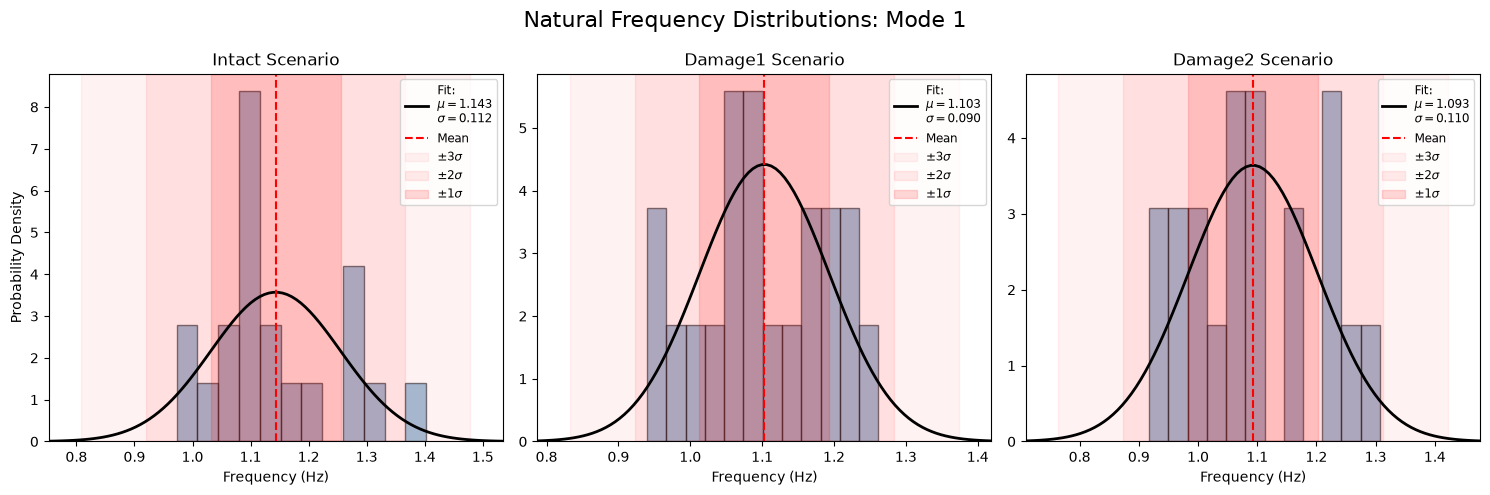

**Figure 1.** Frequency Distributions (Intact vs Damage Scenarios for Mode 1) with $\pm 1-3\sigma$ bands.

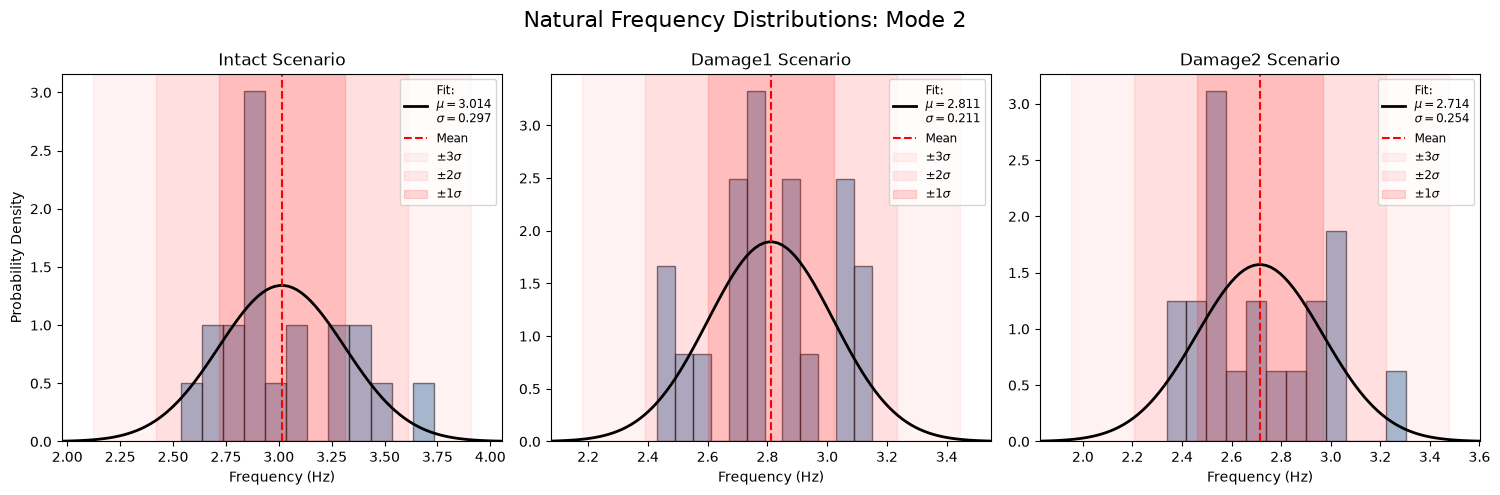

**Figure 2.** Frequency Distributions (Intact vs Damage Scenarios for Mode 2) with $\pm 1-3\sigma$ bands.

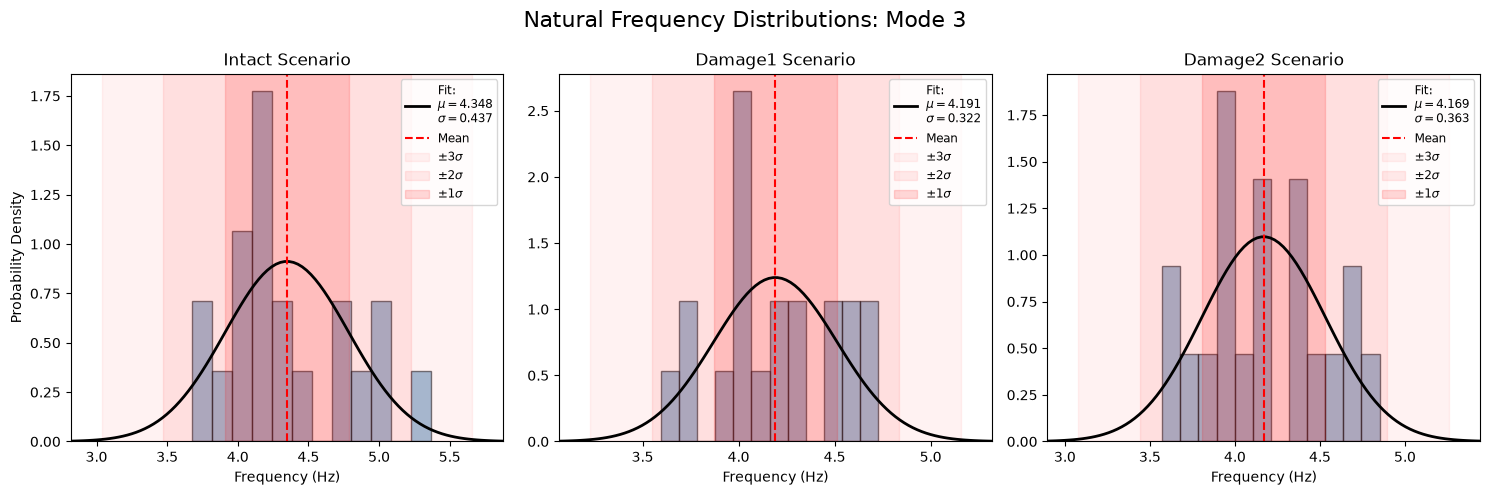

**Figure 3.** Frequency Distributions (Intact vs Damage Scenarios for Mode 3) with $\pm 1-3\sigma$ bands.

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

# Set your starting figure number here based on previous cells
start_fig_num = 1

for i, mode in enumerate(MODES):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    mode_name = mode.replace("_", " ").title()
    fig.suptitle(f'Natural Frequency Distributions: {mode_name}', fontsize=16)

    for j, sc in enumerate(SCENARIOS):
        ax = axes[j]
        data = freqs[sc][:, i]

        # Fit Gaussian distribution
        mu, std = stats.norm.fit(data)

        # Plot frequency histogram with smaller bins (increased from 8 to 12)
        ax.hist(data, bins=12, density=True, alpha=0.5, color='steelblue', edgecolor='black')

        # Overlay fitted PDF
        xmin, xmax = ax.get_xlim()
        # Widen the x-axis slightly to ensure 3 sigma is visible
        x_range = max(xmax - mu, mu - xmin, 3.5 * std)
        x = np.linspace(mu - x_range, mu + x_range, 100)
        p = stats.norm.pdf(x, mu, std)
        ax.plot(x, p, 'k', linewidth=2, label=f'Fit:\n$\\mu={mu:.3f}$\n$\\sigma={std:.3f}$')

        # Vertical line at mean
        ax.axvline(mu, color='red', linestyle='dashed', linewidth=1.5, label='Mean')

        # Shaded regions for 1, 2, and 3 standard deviations
        # Layered from largest to smallest so the overlapping opacities compound correctly
        ax.axvspan(mu - 3*std, mu + 3*std, color='red', alpha=0.05, label='$\pm 3\\sigma$')
        ax.axvspan(mu - 2*std, mu + 2*std, color='red', alpha=0.08, label='$\pm 2\\sigma$')
        ax.axvspan(mu - std, mu + std, color='red', alpha=0.15, label='$\pm 1\\sigma$')

        # Formatting
        ax.set_title(f'{sc.capitalize()} Scenario')
        ax.set_xlabel('Frequency (Hz)')
        ax.set_xlim(mu - x_range, mu + x_range)
        if j == 0:
            ax.set_ylabel('Probability Density')

        # Adjust legend to fit all the new shading labels
        ax.legend(loc='upper right', fontsize='small')

    plt.tight_layout()

    # Use the notebook's built-in function to save and display
    fig_num = start_fig_num + i
    caption = f"Frequency Distributions (Intact vs Damage Scenarios for {mode_name}) with $\pm 1-3\\sigma$ bands."
    filename = f"{mode}_freq_dist_3sigma.png"

    show_figure(fig, fig_num, caption, 'part-a', filename)

When investigating damage scenarions 1 and 2 for each mode shape, have the following observations from Figures 1 to 3:

- The mean of each natural frequency decreases for both damage scenarios compared to the baseline, with the natural frequencies decreasing the most in damage scenario 2
- The standard deviation of natural frequency also decreases for both damage scenarios compared to the intact baseline, with damage scenario 1 having the smallest standard deviation for each mode shape.

The first observation is expected, as structural damage will cause a localized decrease in stiffness, resulting in the overall natural frequency of the structure decreasing (natural frequency is proportional to stiffness and mass). Therefore, when more damage is caused to the structure, the mean natural frequency decreases more and more for each mode. The second observation implies that the variation between measurements decreases for the damage scenarios, which is not an expected outcome as there should be more variation in the system's response to disturbances with damage. This result could be caused by a variety of factors, including temperature, local traffic, and other conditions. Additionally, each mode shape has different amplitudes along the bridge deck, and if the damage occured at a place where all investigated mode shapes have a low amplitude, the resulting damage may not appear as strongly.

Mode 2 shows the strongest sensitivity to structural damage, as seen by the largest decrease in mean natural frequncy of 0.3 Hz for damage scenario 2 compared to the baseline for Group 6's sensors. It's noted that this observation is made before normalization, however, as mode shape 1 has relatively little change and mode shape 3's decrease is already smaller, the same conclusion would be made from normalized data.

The reason mode 2 shows the strongest sensitivty is because the damage must have occured somewhere along mode 2's shape that has a higher amplitude than both modes 1 and 3. This will be further explored in Sections A2 and A3 when the mode shapes are investigated through both visualization and using modal assurance criterion (MAC).

It's noted that the standard deviations also shift for the damage scenarios compared to the baseline intact scenario. It's seen that the standard deviations are proportional to each natural frequency, where for damage scenario 1 each of the standard deviations if the lowest. There is no significant outliers for standard deviations between modes, and therefore the conclusion for the most sensitive mode is mainly drawn from the mean values of the natural frequency distributions.

### A2. Mode Shape Visualization (9 pts)

For Section A2, the mode shapes for each mode and damage scenario have been plotted below in Figure 4. For each of the sub-plotted figures, the x-axis indicates the position along the bridge deck, and y-axis indicates the normalized mode shape amplitude. Shaded regions have been added to each subplot showing one standard deviation variation from the mean from each mode shape.

<>:9: SyntaxWarning: invalid escape sequence '\p'
<>:28: SyntaxWarning: invalid escape sequence '\p'
<>:50: SyntaxWarning: invalid escape sequence '\p'
<>:9: SyntaxWarning: invalid escape sequence '\p'
<>:28: SyntaxWarning: invalid escape sequence '\p'
<>:50: SyntaxWarning: invalid escape sequence '\p'
C:\Users\amilc\AppData\Local\Temp\ipykernel_26032\311828370.py:9: SyntaxWarning: invalid escape sequence '\p'
  fig.suptitle('Mode Shapes: Mean and $\pm 1$ Standard Deviation', fontsize=16)
C:\Users\amilc\AppData\Local\Temp\ipykernel_26032\311828370.py:28: SyntaxWarning: invalid escape sequence '\p'
  ax.fill_between(SENSOR_POS, mean_shape - std_shape, mean_shape + std_shape, color='indigo', alpha=0.2, label='$\pm 1\\sigma$')
C:\Users\amilc\AppData\Local\Temp\ipykernel_26032\311828370.py:50: SyntaxWarning: invalid escape sequence '\p'
  caption = "Mean mode shapes and standard deviation boundaries ($\pm 1\sigma$) across 20 measurements for all structural conditions."


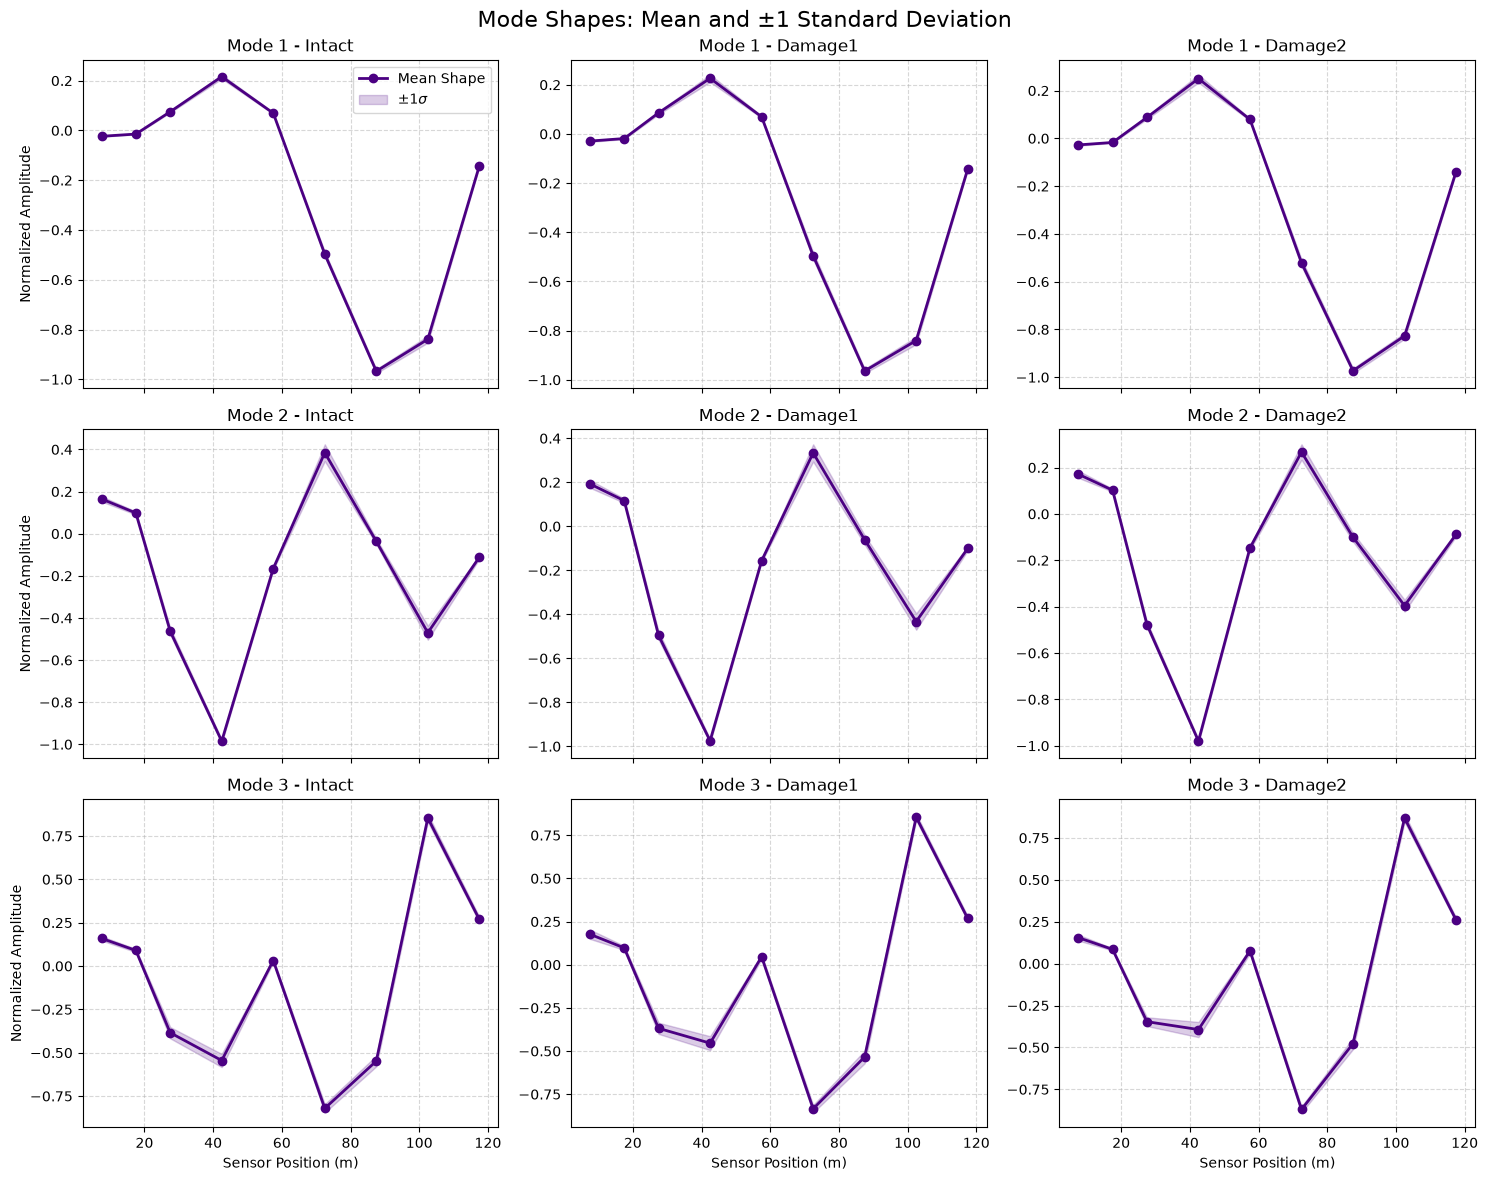

**Figure 4.** Mean mode shapes and standard deviation boundaries ($\pm 1\sigma$) across 20 measurements for all structural conditions.

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Set the figure number for this comprehensive plot
fig_num = 4

# Create a 3x3 subplot layout: rows = modes, columns = scenarios
fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharex=True)
fig.suptitle('Mode Shapes: Mean and $\pm 1$ Standard Deviation', fontsize=16)

for i, mode in enumerate(MODES):
    for j, sc in enumerate(SCENARIOS):
        ax = axes[i, j]

        # Extract mode shape data for this mode and scenario
        # shapes[sc] shape is (modes, measurements, sensors) -> (3, 20, 9)
        # We want mode i, all 20 measurements, all 9 sensors
        data = shapes[sc][i, :, :]

        # Calculate mean and standard deviation across the 20 measurements (axis 0)
        mean_shape = np.mean(data, axis=0)
        std_shape = np.std(data, axis=0)

        # Plot mean mode shape as a solid line
        ax.plot(SENSOR_POS, mean_shape, color='indigo', linestyle='-', marker='o', linewidth=2, label='Mean Shape')

        # Add shaded region for mean +/- 1 standard deviation
        ax.fill_between(SENSOR_POS, mean_shape - std_shape, mean_shape + std_shape, color='indigo', alpha=0.2, label='$\pm 1\\sigma$')

        # Formatting
        mode_name = mode.replace('_', ' ').title()
        ax.set_title(f'{mode_name} - {sc.capitalize()}')
        ax.grid(True, linestyle='--', alpha=0.5)

        # X-axis label only on the bottom row
        if i == 2:
            ax.set_xlabel('Sensor Position (m)')

        # Y-axis label only on the first column
        if j == 0:
            ax.set_ylabel('Normalized Amplitude')

        # Add legend to the first subplot only to avoid clutter
        if i == 0 and j == 0:
            ax.legend(loc='best')

plt.tight_layout()

# Apply the built-in figure saving and captioning function
caption = "Mean mode shapes and standard deviation boundaries ($\pm 1\sigma$) across 20 measurements for all structural conditions."
filename = "mode_shapes_3x3.png"
show_figure(fig, fig_num, caption, 'part-a', filename)

The mode shape uncertainty (or standard deviation) is expected to increase with damage, as material property degredation causes more variation in the system response to disturbances. From Figure 4, this is most strongly seen in the following cases:

- Mode Shape 1: Sensors S6, S9, and S12 covering the span from 27.5m to 57.5m show increased variation for damage scenarios 1 and 2 compared to the baseline intact scenario.
- Mode Shape 2: Sensors S12, S15, S18, S21, and S24 covering the span from 57.5m to 117.5m show slightly increased variation for damage scenario 1, while damage scenario 2 has similar to the intact scenario.
- Mode Shape 2: Sensors S2 and S4, covering the span from 7.5m to 17.5m, shows larger variation for damage scenarios 1 and 2 compared to the intact baseline scenario.
- Mode Shape 3: Similar to Mode 2, Sensors S2 and S4 show larger variation for damage scenarios.
- Mode Shape 3: Sensors S6 to S9 covering span 27.5m to 42.5m show larger variation for damage scenarios 1 and 2 compared to the baseline intact scenario. It's noted that the span between S9 and S12 does not increase in variation between scenarios, but does have a larger margin.

For all other spans, any variations present are already seen in the intact scenario, and are more likely the result of other natural variations such as temperature, traffic, or pre-existing stuctural conditions.

From Phase 1, it's known that the damage to the bridge lies mostly within the middle region, where sensor S12 showed the highest change in COMAC. From the mode shape variability, in general yes damaged regions do show increased variability, but not all the time and not in consistent locations. This is noted from the previous observations, where different increases in variations were noted for different mode shapes. Modes 1 and 3 show higher variability in the left-of-middle section if the bridge, while Mode 2 shows higher variability near the right-of-middle section. Depending on the location of damage, different mode shapes will be affected differently depending on their amplitude at the damage location, which leads to this observed discrepency.



### A3. Modal Assurance Criterion (MAC) Distributions (8 pts)

For Section A3, the Modal Assurance Criterion (MAC) distributions for each Mode shape and damage scenario have been plotted below in Figures 5 to 7, with a summary of the mean and standard deviations reported in Table 6. Note that for determining MAC, the reference intact scenario provided has been used, however, Group 6's data only consists of only 9 sensors, and therefore there will be some differences for the intact scenario between the reference intact scenario and the Group 6 intact scenario that is seen in Figure 5.

**Table 6.** Summary of MAC statistics (mean and standard deviation) compared to intact reference.

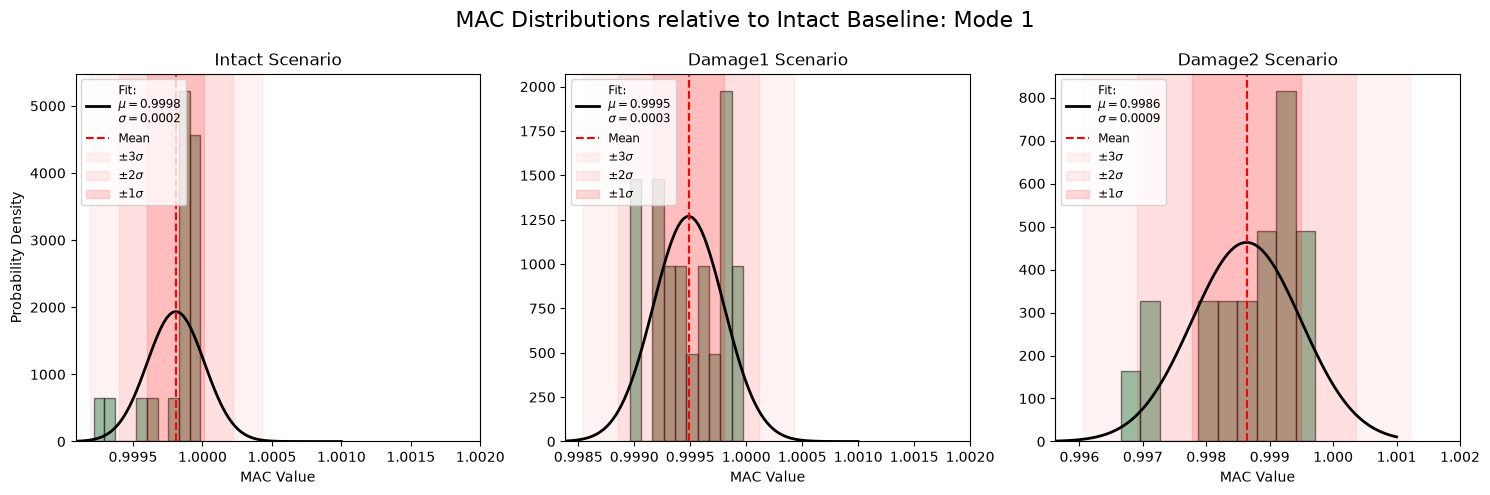

**Figure 5.** MAC distribution histograms and fitted Gaussian curves relative to intact baseline for Mode 1.

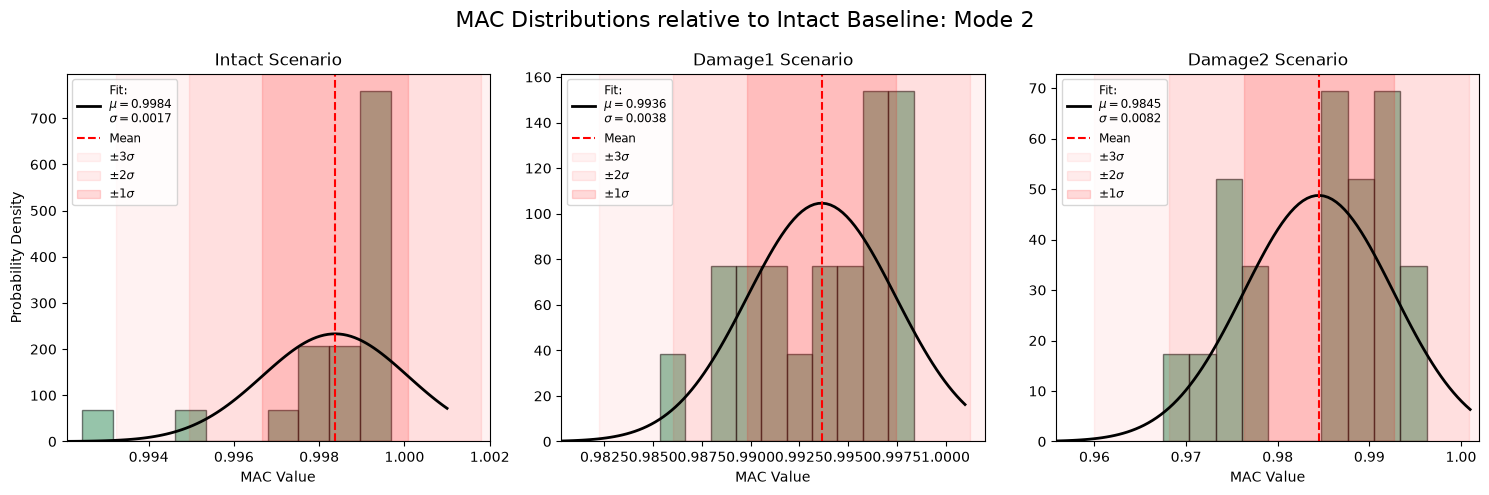

**Figure 6.** MAC distribution histograms and fitted Gaussian curves relative to intact baseline for Mode 2.

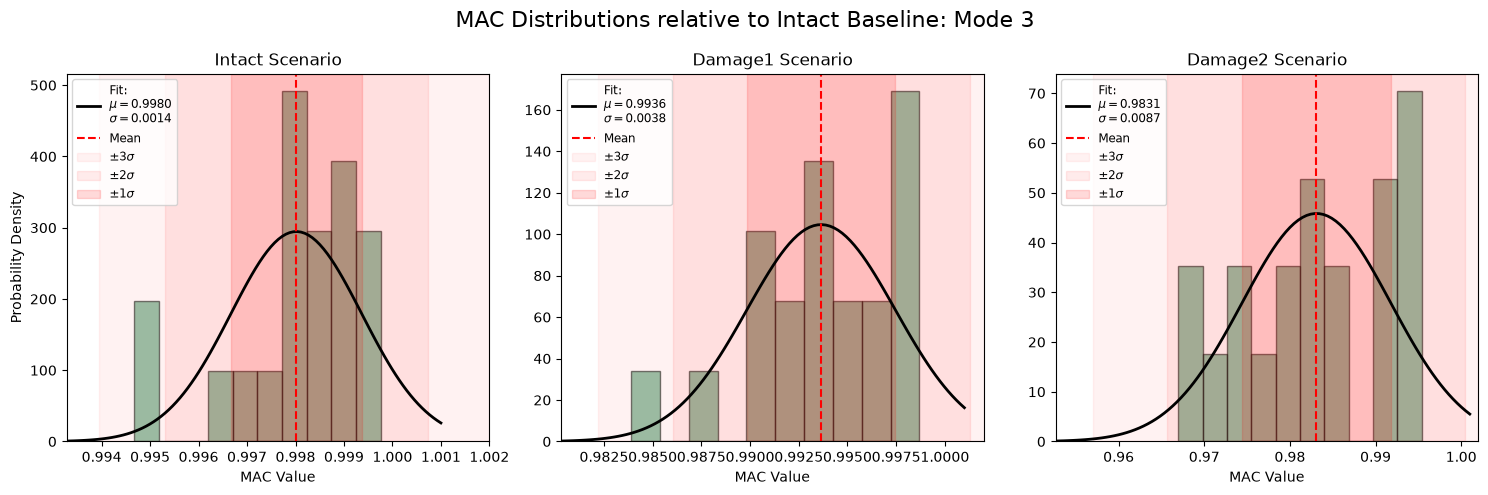

**Figure 7.** MAC distribution histograms and fitted Gaussian curves relative to intact baseline for Mode 3.

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy.stats as stats

# 1. Define MAC calculation function
def compute_mac(phi_a, phi_b):
    """Compute Modal Assurance Criterion (MAC) between two mode shape vectors."""
    num = np.abs(np.dot(phi_a, phi_b))**2
    den = np.dot(phi_a, phi_a) * np.dot(phi_b, phi_b)
    return num / den

# 2. Calculate intact reference mean mode shapes (3 modes x 9 sensors)
# shapes['intact'] shape is (3, 20, 9) -> mean across axis 1 (20 measurements)
ref_shapes = {i: np.mean(shapes['intact'][i, :, :], axis=0) for i in range(len(MODES))}

# 3. Compute MAC values for each mode and scenario (20 estimates vs intact reference)
mac_results = {sc: np.zeros((N_MEAS, len(MODES))) for sc in SCENARIOS}
mac_stats_list = []

for i, mode in enumerate(MODES):
    phi_ref = ref_shapes[i]
    for sc in SCENARIOS:
        for m_idx in range(N_MEAS):
            phi_meas = shapes[sc][i, m_idx, :]
            mac_results[sc][m_idx, i] = compute_mac(phi_meas, phi_ref)

        # Store mean and std for summary table
        mu_mac = np.mean(mac_results[sc][:, i])
        std_mac = np.std(mac_results[sc][:, i])
        mac_stats_list.append({
            'Mode': mode.replace('_', ' ').title(),
            'Scenario': sc.capitalize(),
            'Mean MAC (μ)': mu_mac,
            'Std Dev (σ)': std_mac
        })

# Display summary table using notebook helper
mac_summary_df = pd.DataFrame(mac_stats_list).set_index(['Mode', 'Scenario'])
show_table(mac_summary_df, 6, "Summary of MAC statistics (mean and standard deviation) compared to intact reference.",
           filename="mac_summary_statistics.csv", precision=4)

# 4. Generate MAC Histogram Figures (One figure per mode, starting at Figure 5)
start_fig_num = 5

for i, mode in enumerate(MODES):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    mode_name = mode.replace("_", " ").title()
    fig.suptitle(f'MAC Distributions relative to Intact Baseline: {mode_name}', fontsize=16)

    for j, sc in enumerate(SCENARIOS):
        ax = axes[j]
        data = mac_results[sc][:, i]

        # Fit Gaussian distribution using MLE
        mu, std = stats.norm.fit(data)

        # Plot MAC histogram with fine binning
        ax.hist(data, bins=10, density=True, alpha=0.5, color='seagreen', edgecolor='black')

        # Overlay fitted PDF
        xmin, xmax = ax.get_xlim()
        # Force lower x-bound to accommodate 3-sigma if MAC stays high
        x_min_plot = min(xmin, mu - 3.5 * std)
        x = np.linspace(x_min_plot, 1.001, 100)
        p = stats.norm.pdf(x, mu, std)
        ax.plot(x, p, 'k', linewidth=2, label=f'Fit:\n$\\mu={mu:.4f}$\n$\\sigma={std:.4f}$')

        # Vertical line at mean and shaded 1-3 sigma regions
        ax.axvline(mu, color='red', linestyle='dashed', linewidth=1.5, label='Mean')
        ax.axvspan(mu - 3*std, mu + 3*std, color='red', alpha=0.05, label=r'$\pm 3\sigma$')
        ax.axvspan(mu - 2*std, mu + 2*std, color='red', alpha=0.08, label=r'$\pm 2\sigma$')
        ax.axvspan(mu - std, mu + std, color='red', alpha=0.15, label=r'$\pm 1\sigma$')

        # Formatting
        ax.set_title(f'{sc.capitalize()} Scenario')
        ax.set_xlabel('MAC Value')
        ax.set_xlim(x_min_plot, 1.002)
        if j == 0:
            ax.set_ylabel('Probability Density')
        ax.legend(loc='upper left', fontsize='small')

    plt.tight_layout()

    # Save and display figure with built-in helper
    fig_num = start_fig_num + i
    caption = r"MAC distribution histograms and fitted Gaussian curves relative to intact baseline for " + mode_name + r"."
    filename = f"{mode}_mac_distributions.png"
    show_figure(fig, fig_num, caption, 'part-a', filename)

MAC determines the variation in mode shape, so a MAC value of 1 indicates the mode shape is the same across measurements. We are measuring the scenarios from the data collected from Group 6's sensors to the reference intact scenario provided. As group 6 is only using data from 9 of the sensors, the results will be different for the "Group 6 intact" scenario compared to the "reference scenario", but should still be fairly similar. As seen from Figures 5 to 7, this is confirmed by the MAC mean of the Group 6 intact scenario being 0.998 compared to the reference scenario, showing the values are close with a small standard deviation of 0.0002.

When damage is applied, the mode shapes of the structure will change due to structural property changes in the stiffness of the bridge deck. This will be reflected in the mean value of the distribution shifting below 1, with a lower mean MAC score suggesting more severe damage (deviation from the intact, undamaged scenario). The standard deviation of the MAC distribution will also increase as the structure responds more to system disturbances. Mode shapes will change differently depending on where the damage has occured. If the mode shape has a low amplitude (or zero) and only localized damage has occured, the mode shape will appear unchanged as the small amplitude will not be affected. Alternatively, if the mode shape has a high amplitude where damage has occured, the mode shape will show a large deviation from the intact scenario, indicating the position of damage.

Therefore, MAC distributions are affected by damage, but the impact for each mode shape will be different depending on how much of the structure is impacted. The mean MAC score will decrease and the standard deviation will increase when damage is present, with a MAC score close to 1 suggesting the mode shapes are similar, and a MAC close to 0 showing they are completely uncorrelated.

From the sensors considered for Group 6, mode shape 3 shows the clearest separation from baseline conditions. This is reflected through:

- The biggest decrease in MAC mean compared to the intact scenario, with a mean MAC of 0.9831 for damage scenario 2.
- The largest MAC distribution standard deviation in damage scenario 2 of 0.0087

Mode shape 1 shows the least separation from the baseline conditions, with small mean changes across each tested scenario. Mode shapes 2 and 3 show the exact same decrease in MAC for damage scenario 1, both having a mean of 0.9936 and standard deviation of 0.0038. Damage Scenario 2 is where the main difference is seen between mode shapes 2 and 3, with mode shape 3 showing the bigger shift from 1. Therefore, conclude that mode shape 3 shows the clearest separation from baseline reference intact conditions.



<a id="part-b"></a>
## Part B: Single Feature Damage Detection (20 pts)

In this section, features $f_1$, $f_2$, $f_3$, $MAC_1$, $MAC_2$, and $MAC_3$ are all analyzed individually. Natural frequency values are taken from the given values for natural frequencies for each mode, and the MAC values were computed using the sensors assigned specifically to Group 6. Note that each feature has a total of 20 measurements taken.

### B1. Z-Score Anomaly Detection (10 pts)

For each feature ($f_1$, $f_2$, $f_3$, $MAC_1$, $MAC_2$, and $MAC_3$), the intact measurements were used to establish a baseline scenario, and the mean and standard deviations were extracted from each array of values. Following the establishment of the baseline, the values from the damage1 and damage2 scenario were used to calculate the Z-score (number of deviations away from the mean) using Equation (1). Any feature observations that were found to have an absolute Z-score greater than 2 were flagged as anomalies in the data, which corresponds to a 95% confidence level in detection. From the flagged observations, the percentage of damaged measurements correctly flagged was calculated for each feature. The following Z-score analysis, anomaly flagging, and correct damage flagged percentages are shown below in Table 7.

$$z = \frac{x - \mu_0}{\sigma_0} \tag{1}$$

Where:

- $x$: The measured value for a given feature.
- $\mu_0$: the baseline mean value calculated from intact scenario for a given feature.
- $\sigma_0$: the baseline standard deviation value calculated from intact scenario for a given feature.



In [11]:
import numpy as np
import pandas as pd

# 1. Consolidate all six features into a single dictionary for easy iteration
feature_data = {sc: {} for sc in SCENARIOS}

for sc in SCENARIOS:
    for i in range(3):
        # Store frequencies and MACs with 1-based indexing (f1, f2, f3, MAC1, MAC2, MAC3)
        feature_data[sc][f'f{i+1}'] = freqs[sc][:, i]
        feature_data[sc][f'MAC{i+1}'] = mac_results[sc][:, i]

feature_names = [f'f{i+1}' for i in range(3)] + [f'MAC{i+1}' for i in range(3)]

# 2. Compute baseline statistics, Z-score metrics, and detection rates
summary_stats = []
intact_false_alarms = {}  # intact measurements with |z| > 2 (false alarms), used in Part F

for feat in feature_names:
    # Compute baseline statistics (μ0, σ0) using intact measurements
    x_intact = feature_data['intact'][feat]
    mu0 = np.mean(x_intact)
    sigma0 = np.std(x_intact)
    intact_false_alarms[feat] = int(np.sum(np.abs((x_intact - mu0) / sigma0) > 2))

    row = {
        'Feature': feat,
        'Baseline Mean (μ0)': mu0,
        'Baseline Std (σ0)': sigma0,
    }

    # Calculate Z-scores and metrics for damage scenarios
    for sc in ['damage1', 'damage2']:
        x_damaged = feature_data[sc][feat]

        # Calculate Z-score for each measurement
        z_scores = (x_damaged - mu0) / sigma0

        # Flag observations where |z| > 2
        anomalies = np.abs(z_scores) > 2
        detection_rate = (np.sum(anomalies) / len(anomalies)) * 100

        # Add summary Z-score information and detection rates to the row
        row[f'{sc.capitalize()} Mean Z'] = np.mean(z_scores)
        row[f'{sc.capitalize()} Max |Z|'] = np.max(np.abs(z_scores))
        row[f'{sc.capitalize()} Detection Rate (%)'] = detection_rate

    summary_stats.append(row)

# 3. Create DataFrame and display using the built-in helper
detection_summary_df = pd.DataFrame(summary_stats).set_index('Feature')

show_table(detection_summary_df, 7,
           "Z-score anomaly detection summary: Baseline statistics, Mean Z-score, Maximum Absolute Z-score, and detection rates (|z| > 2).",
           filename="univariate_zscore_detection.csv", precision=4)

**Table 7.** Z-score anomaly detection summary: Baseline statistics, Mean Z-score, Maximum Absolute Z-score, and detection rates (|z| > 2).

,Baseline Mean (μ0),Baseline Std (σ0),Damage1 Mean Z,Damage1 Max |Z|,Damage1 Detection Rate (%),Damage2 Mean Z,Damage2 Max |Z|,Damage2 Detection Rate (%)
Feature,,,,,,,,
f1,1.1433,0.1118,-0.3605,1.8221,0.0000,-0.4526,2.0221,5.0000
f2,3.0142,0.2974,-0.6822,1.9668,0.0000,-1.0094,2.2744,10.0000
f3,4.3478,0.4374,-0.3581,1.7217,0.0000,-0.4083,1.7724,0.0000
MAC1,0.9998,0.0002,-1.5645,4.1165,45.0000,-5.6937,15.3304,85.0000
MAC2,0.9984,0.0017,-2.7681,7.6104,50.0000,-8.1248,18.0749,95.0000
MAC3,0.9980,0.0014,-3.2271,10.4265,55.0000,-11.0222,22.9153,95.0000


As seen from Table 7, have the following summarized observations:

- The damage rate detection from natural frequencies is significantly worse performing compared to the MAC detection rate. On average, damage was successfully flagged 2.5% of the time using natural frequency Z-score analysis, while damage was successfully flagged 79.2% of the time.
- Damage Scenario 2's damage detection rate was higher than damage scenario 1 for both natural frequency and MAC features.
- No damage was flagged at all from any of the natural frequencies for damage scenario 1, and only 50% of the time for MAC Z-Scores for damage scenario 1.

From these observations, for using Z-score analysis, it was found that MAC is the overall better performing feature for detecting damage, as it has better flagging performance than natural frequency in all cases for the three analyzed modes. Additionally, the flagging accuracy of both natural frequency and MAC increased for damage scenario 2 when more damage is present, so both are sensitive to the amount of damage present.

### B2. Wasserstein Distance Analysis (7 pts)

For each of the features ($f_1$, $f_2$, $f_3$, $MAC_1$, $MAC_2$, and $MAC_3$), the Wasserstein distances were calculated between the intact distribution and damage distributions. The values were then normalized to allow for fair comparison across features with different units and scales, and the results were tabulated in Table 8. Additionally, a graph was created showing the normalized Wasserstein distances for each feature for both damage scenarios in Figure 8, with the Z-score of 2 threshold added for reference to compare results with Section B1.

**Table 8.** Wasserstein distances ($W_1$) and normalized distances ($W_{1,\text{norm}} = W_1/\sigma_0$) relative to the intact baseline.

,Baseline Std (σ0),Raw W1 (Damage 1),Norm W1 (Damage 1),Raw W1 (Damage 2),Norm W1 (Damage 2)
Feature,,,,,
f1,0.1118,0.0404,0.3613,0.0506,0.4526
f2,0.2974,0.2029,0.6822,0.3002,1.0094
f3,0.4374,0.1600,0.3658,0.1816,0.4152
MAC1,0.0002,0.0003,1.5645,0.0012,5.6937
MAC2,0.0017,0.0047,2.7681,0.0139,8.1248
MAC3,0.0014,0.0044,3.2271,0.0149,11.0222


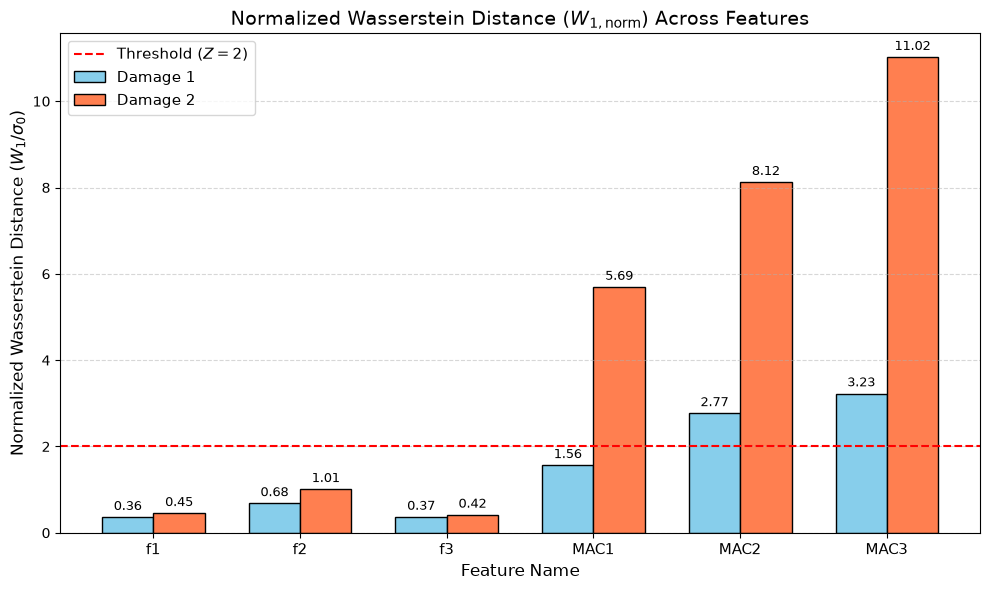

**Figure 8.** Comparison of normalized Wasserstein distance ($W_{1,\text{norm}}$) for all six features across Damage 1 and Damage 2 scenarios.

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

# 1. Consolidate feature data (frequencies f1-f3 and MACs MAC1-MAC3)
feature_names = [f'f{i+1}' for i in range(3)] + [f'MAC{i+1}' for i in range(3)]
feature_data = {sc: {} for sc in SCENARIOS}

for sc in SCENARIOS:
    for i in range(3):
        feature_data[sc][f'f{i+1}'] = freqs[sc][:, i]
        feature_data[sc][f'MAC{i+1}'] = mac_results[sc][:, i]

# 2. Compute Raw and Normalized Wasserstein Distances
w1_results = []
w1_dict = {'damage1': [], 'damage2': []}

for feat in feature_names:
    x_intact = feature_data['intact'][feat]
    sigma0 = np.std(x_intact)

    # Compute Wasserstein distance for Damage 1 and Damage 2
    w1_d1 = stats.wasserstein_distance(x_intact, feature_data['damage1'][feat])
    w1_d2 = stats.wasserstein_distance(x_intact, feature_data['damage2'][feat])

    # Normalize by baseline standard deviation
    w1_norm_d1 = w1_d1 / sigma0
    w1_norm_d2 = w1_d2 / sigma0

    # Store normalized values for plotting
    w1_dict['damage1'].append(w1_norm_d1)
    w1_dict['damage2'].append(w1_norm_d2)

    w1_results.append({
        'Feature': feat,
        'Baseline Std (σ0)': sigma0,
        'Raw W1 (Damage 1)': w1_d1,
        'Norm W1 (Damage 1)': w1_norm_d1,
        'Raw W1 (Damage 2)': w1_d2,
        'Norm W1 (Damage 2)': w1_norm_d2
    })

# 3. Create Summary Table and Display
w1_df = pd.DataFrame(w1_results).set_index('Feature')

show_table(
    w1_df,
    8,
    r"Wasserstein distances ($W_1$) and normalized distances ($W_{1,\text{norm}} = W_1/\sigma_0$) relative to the intact baseline.",
    filename="wasserstein_distance_summary.csv",
    precision=4
)

# 4. Grouped Bar Chart comparing Normalized Wasserstein Distance across all 6 features
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(feature_names))  # Label locations
width = 0.35  # Bar width

rects1 = ax.bar(x - width/2, w1_dict['damage1'], width, label='Damage 1', color='skyblue', edgecolor='black')
rects2 = ax.bar(x + width/2, w1_dict['damage2'], width, label='Damage 2', color='coral', edgecolor='black')

# Add values on top of bars for readability
ax.bar_label(rects1, padding=3, fmt='%.2f', fontsize=9)
ax.bar_label(rects2, padding=3, fmt='%.2f', fontsize=9)

# Axis formatting and labeling
ax.set_xlabel('Feature Name', fontsize=12)
ax.set_ylabel(r'Normalized Wasserstein Distance ($W_1 / \sigma_0$)', fontsize=12)
ax.set_title(r'Normalized Wasserstein Distance ($W_{1,\text{norm}}$) Across Features', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(feature_names, fontsize=11)
ax.axhline(2.0, color='red', linestyle='--', linewidth=1.5, label=r'Threshold ($Z=2$)')
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='upper left', fontsize=11)

plt.tight_layout()

# Save and show figure using notebook helper
fig_num = 8
caption = r"Comparison of normalized Wasserstein distance ($W_{1,\text{norm}}$) for all six features across Damage 1 and Damage 2 scenarios."
filename = "wasserstein_distance_grouped_bars.png"

show_figure(fig, fig_num, caption, 'part-b', filename)

As seen from the normalized Wasserstein distances in Table 8 and Figure 8, have the following observations:

- The Wassterstein distances are significantly larger for MAC features compared to natural frequency features, suggesting there is substantially more difference in the MAC distributions (damage vs intact) compared to the differences in natural frequency distributions (damage vs intact).
- Within the natural frequency features, $f_2$ has the greatest normalized Wasserstein distance, while $f_1$ and $f_3$ vary between damage scenarios.
- Using a Z-Score of 2, similar to what was done in Part B1, no damage would be detected using Wasserstein distances for any of the natural frequencies.
- For the MAC features, MAC3 had the highest normalized Wasserstein distances, followed by MAC2 and MAC1.
- If a Z-Score of 2 was considered like in Section B1, all the MAC damage scenarios except damage1 for MAC1 would have reported damage is present.

These observations are similar to those in the previous section, where the MAC features are better for detecting whether damage is present, and the natural frequencies are less sensitive to damage. Further explanation regarding these factors follows in Section B3.

### B3. Feature Sensitivity Ranking (3 pts)

From the Z-Score and Wasserstein distances analysis', have the following ranking for the tested features $f_1$, $f_2$, $f_3$, $MAC_1$, $MAC_2$, and $MAC_3$ for damage detection performance:

1. $MAC_3$
2. $MAC_2$
3. $MAC_1$
4. $f_2$
5. $f_1$
6. $f_3$

The ranking was determined from the following logic for both the Z-Score analysis and Wasserstein distance analysis:

From the Z-Score analysis, it was found that for damage scenario 2, $MAC_2$ and $MAC_3$ had the highest correct damage detection, with $MAC_3$ performing 5% better for damage scenario 1. Additionally, $MAC_3$ had the largest normalized Wasserstein distance in Section B2, with $MAC_2$ following close in second. $MAC_1$ had worse damage detection performance in both the Z-score and Wasserstein distance analysis', however, still performed significantly better compared to the natural frequency features.

For the natural frequency analysis, $f_2$ had the highest correct damage flagged percentage from the Z-score analysis of 10% compared to the other natural frequencies, and also had the highest Wasserstein distance compared to the other natural frequencies. Following $f_2$, $f_1$ had the second highest correct damage flagged percentage at 5% from the Z-Score analysis, and $f_3$ had the lowest with 0% (or none) correctly flagged damage measurements. The Wasserstein distance analysis showed $f_1$ and $f_3$ performed similarly, and therefore $f_1$ was given a higher ranking due to the Z-score analysis.

Therefore, overall $MAC_3$ was the most damage-sensitive feature, while $f_3$ was the least damage-sensitive feature. In general, it was found that the MAC features perform significantly better than natural frequencies for detecting damage. This observation was expected, as natural frequencies are dependent on the dynamics of the entire bridge deck, where localized damage will not have a great impact. Comparitively, mode shapes can be highly influenced by local damage, which is captured in the recorded MAC measurements for each mode.

<a id="part-c"></a>
## Part C: Bivariate Analysis (20 pts)

### C1. Joint Distribution Visualization (7 pts)

Two pairs of variables are analyzed: $(f_1, f_2)$ and $(\mathrm{MAC}_1, \mathrm{MAC}_2)$.

The Modal Assurance Criterion (MAC) was calculated with the following equation:

$$
\mathrm{MAC} = \frac{\left(\boldsymbol{\phi}_{ref}^{T}\,\boldsymbol{\phi}_{test}\right)^{2}}{\left(\boldsymbol{\phi}_{ref}^{T}\boldsymbol{\phi}_{ref}\right)\left(\boldsymbol{\phi}_{test}^{T}\boldsymbol{\phi}_{test}\right)}
\tag{2}
$$

Where:

- $\boldsymbol{\phi}_{ref}$: reference mode shape, equal to the average of the 20 measurements of the intact scenario (9 values, one per sensor).
- $\boldsymbol{\phi}_{test}$: mode shape of one measurement (9 values).
- $\boldsymbol{\phi}^{T}\boldsymbol{\phi}$: dot product, that is, the values are multiplied sensor by sensor and the results are added up.

**Table 9.** MAC of modes 1 and 2 for each of the 20 measurements, intact scenario (reference: mean intact mode shape).

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
MAC1,1.0000,0.9999,0.9999,0.9999,0.9999,1.0000,0.9998,0.9996,0.9999,0.9999,0.9993,0.9999,0.9998,1.0000,0.9996,0.9999,0.9992,1.0000,0.9999,0.9999
MAC2,0.9994,0.9991,0.9994,0.9997,0.9952,0.9924,0.9980,0.9987,0.9991,0.9973,0.9991,0.9995,0.9997,0.9977,0.9987,0.9996,0.9985,0.9991,0.9980,0.9994


**Table 10.** MAC of modes 1 and 2 for each of the 20 measurements, damage1 scenario (reference: mean intact mode shape).

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
MAC1,0.9996,0.9994,0.9990,0.9995,0.9992,0.9999,0.9993,0.9990,0.9990,1.0000,0.9993,0.9992,0.9998,0.9998,0.9994,0.9999,0.9992,0.9999,0.9996,0.9997
MAC2,0.9905,0.9932,0.9854,0.9982,0.9883,0.9908,0.9936,0.9969,0.9968,0.9981,0.9963,0.9972,0.9969,0.9901,0.9956,0.9984,0.9925,0.9880,0.9954,0.9906


**Table 11.** MAC of modes 1 and 2 for each of the 20 measurements, damage2 scenario (reference: mean intact mode shape).

Measurement,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
Mode,,,,,,,,,,,,,,,,,,,,
MAC1,0.9971,0.9983,0.9987,0.9966,0.9992,0.9971,0.9981,0.9991,0.9989,0.9993,0.9985,0.9996,0.9993,0.9989,0.9993,0.9997,0.9995,0.9981,0.9982,0.9992
MAC2,0.9719,0.9748,0.9890,0.9738,0.9895,0.9674,0.9918,0.9776,0.9936,0.9866,0.9928,0.9852,0.9908,0.9899,0.9921,0.9863,0.9963,0.9758,0.9854,0.9789


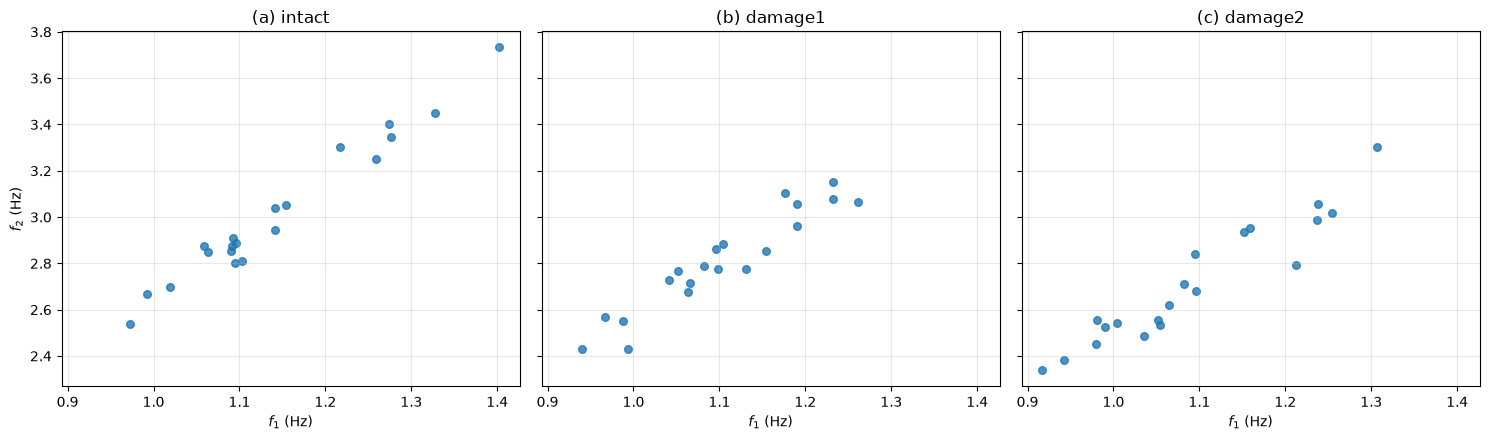

**Figure 9.** Natural frequencies of mode 1 ($f_1$) versus mode 2 ($f_2$) for the 20 measurements of each scenario: (a) intact, (b) damage1, (c) damage2.

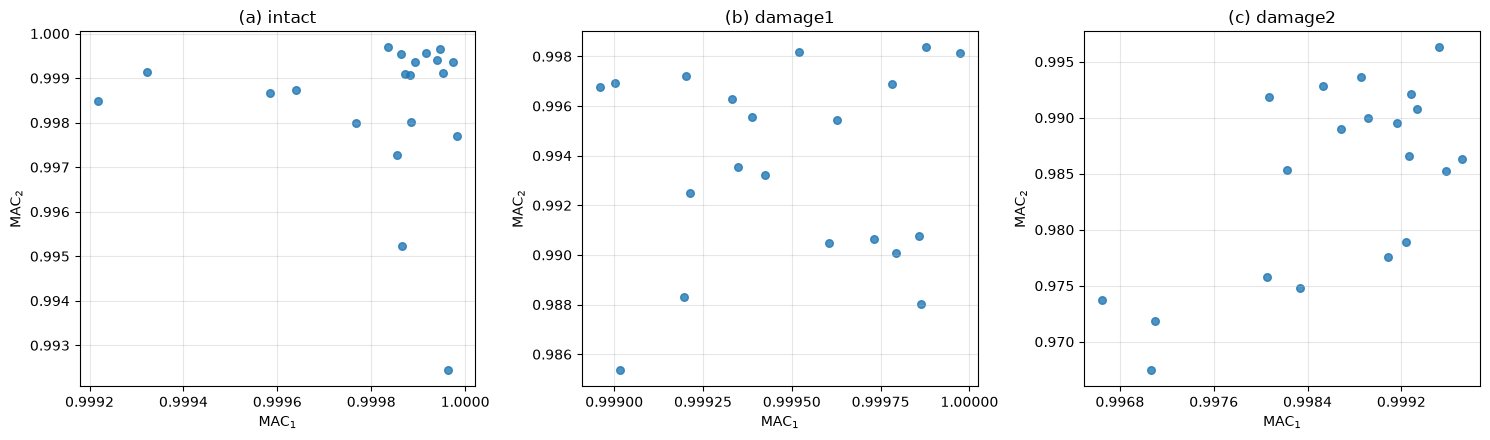

**Figure 10.** MAC of mode 1 ($\mathrm{MAC}_1$) versus MAC of mode 2 ($\mathrm{MAC}_2$) for the 20 measurements of each scenario: (a) intact, (b) damage1, (c) damage2.

In [13]:
# MAC (Eq. 2) of modes 1 and 2 against the mean intact mode shape, taken from Part A3 (mac_results)
MAC_MODES = [0, 1]                               # mode 1 and mode 2 (indices in MODES)

# mac[scenario]: (N_MEAS, 2) array -> measurements x [MAC1, MAC2]
mac = {sc: mac_results[sc][:, MAC_MODES] for sc in SCENARIOS}

# One table per scenario: rows = MAC of each mode, columns = measurements
for t, sc in enumerate(SCENARIOS, start=9):
    mac_table = pd.DataFrame(mac[sc].T,
                             index=pd.Index([f'MAC{j + 1}' for j in MAC_MODES], name='Mode'),
                             columns=pd.RangeIndex(1, N_MEAS + 1, name='Measurement'))
    show_table(mac_table, t, f'MAC of modes 1 and 2 for each of the 20 measurements, {sc} scenario '
               '(reference: mean intact mode shape).', precision=4)


# Scatter of (f1, f2) for each scenario; same axis limits in all panels to compare them
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, sc, label in zip(axes, SCENARIOS, ['(a)', '(b)', '(c)']):
    ax.scatter(freqs[sc][:, 0], freqs[sc][:, 1], s=30, alpha=0.8)
    ax.set_title(f'{label} {sc}')
    ax.set_xlabel('$f_1$ (Hz)')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('$f_2$ (Hz)')
fig.tight_layout()
show_figure(fig, 9, 'Natural frequencies of mode 1 ($f_1$) versus mode 2 ($f_2$) for the 20 measurements of each '
            'scenario: (a) intact, (b) damage1, (c) damage2.', 'part-c', 'C1_f1_f2_scatter.png')

# Scatter of (MAC1, MAC2) for each scenario; each panel scaled to its own data
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, sc, label in zip(axes, SCENARIOS, ['(a)', '(b)', '(c)']):
    ax.scatter(mac[sc][:, 0], mac[sc][:, 1], s=30, alpha=0.8)
    ax.set_title(f'{label} {sc}')
    ax.set_xlabel(r'$\mathrm{MAC}_1$')
    ax.set_ylabel(r'$\mathrm{MAC}_2$')
    ax.xaxis.set_major_locator(plt.MaxNLocator(5))   # fewer ticks so the labels do not overlap
    ax.grid(alpha=0.3)
fig.tight_layout()
show_figure(fig, 10, r'MAC of mode 1 ($\mathrm{MAC}_1$) versus MAC of mode 2 ($\mathrm{MAC}_2$) for the 20 measurements '
            'of each scenario: (a) intact, (b) damage1, (c) damage2.', 'part-c', 'C1_MAC1_MAC2_scatter.png')

The contour of the bivariate Gaussian is calculated with the following formula:

$$(\mathbf{x}-\boldsymbol{\mu}_0)^{T}\,\boldsymbol{\Sigma}_0^{-1}\,(\mathbf{x}-\boldsymbol{\mu}_0) = \chi^2_{p,\,1-\alpha} \tag{3}$$

Where:

- $\mathbf{x}$ is the set of points of the baseline.
- $\boldsymbol{\mu}_0$ is the mean vector of the baseline.
- $\boldsymbol{\Sigma}_0^{-1}$: the inverse of the covariance matrix of the baseline.
- $\chi^2_{p,\,1-\alpha}$: the chi-square value with $p$ degrees of freedom, one per feature, at the confidence level $1-\alpha$. For 2 features at 95 % it is 5.991, and its square root is 2.45.

All the points of the contour are at the same Mahalanobis distance from the center. To draw it, the parametric form is used, which comes from the eigenvalues and eigenvectors of the covariance:

$$\boldsymbol{\Sigma}_0 = \mathbf{V}\boldsymbol{\Lambda}\mathbf{V}^{T}, \qquad \mathbf{x}(\theta) = \boldsymbol{\mu}_0 + \sqrt{\chi^2_{p,\,1-\alpha}}\;\mathbf{V}\,\boldsymbol{\Lambda}^{1/2}\begin{bmatrix}\cos\theta\\ \sin\theta\end{bmatrix} \tag{4}$$

Where:

- $\mathbf{V}$: the eigenvector matrix, which gives the direction of the axes of the ellipse.
- $\boldsymbol{\Lambda}$: the diagonal eigenvalue matrix, with the variance along each axis.
- $\theta$: the angle, from 0 to $2\pi$.

A circle of radius 2.45 is taken, each axis is stretched by the square root of its eigenvalue, then it is rotated with the eigenvectors and moved to the center.

In [14]:
# Bivariate Gaussian fitted to each feature pair and scenario, and its 95 % contour: d^2 = chi2_0.95(2)
CHI2_95 = stats.chi2.ppf(0.95, df=2)             # 5.991

def gaussian_contour(X, level=CHI2_95, n_points=200):
    mu = X.mean(axis=0)                          # mean of each feature
    cov = np.cov(X, rowvar=False, ddof=1)        # 2x2 covariance matrix
    rho = cov[0, 1] / np.sqrt(cov[0, 0] * cov[1, 1])
    # Ellipse d^2 = level: axes along the eigenvectors of cov, semi-axes sqrt(level * eigenvalue)
    eigvals, eigvecs = np.linalg.eigh(cov)
    t = np.linspace(0, 2 * np.pi, n_points)
    circle = np.vstack([np.cos(t), np.sin(t)])
    ellipse = mu + (eigvecs @ (np.sqrt(level * eigvals)[:, None] * circle)).T
    return {'mu': mu, 'cov': cov, 'rho': rho, 'ellipse': ellipse}


# gauss[pair][scenario]: mean, covariance, rho and (n_points, 2) points of the 95 % ellipse
pairs = {'f1-f2': {sc: freqs[sc][:, :2] for sc in SCENARIOS},
         'MAC1-MAC2': mac}
gauss = {pair: {sc: gaussian_contour(X[sc]) for sc in SCENARIOS} for pair, X in pairs.items()}


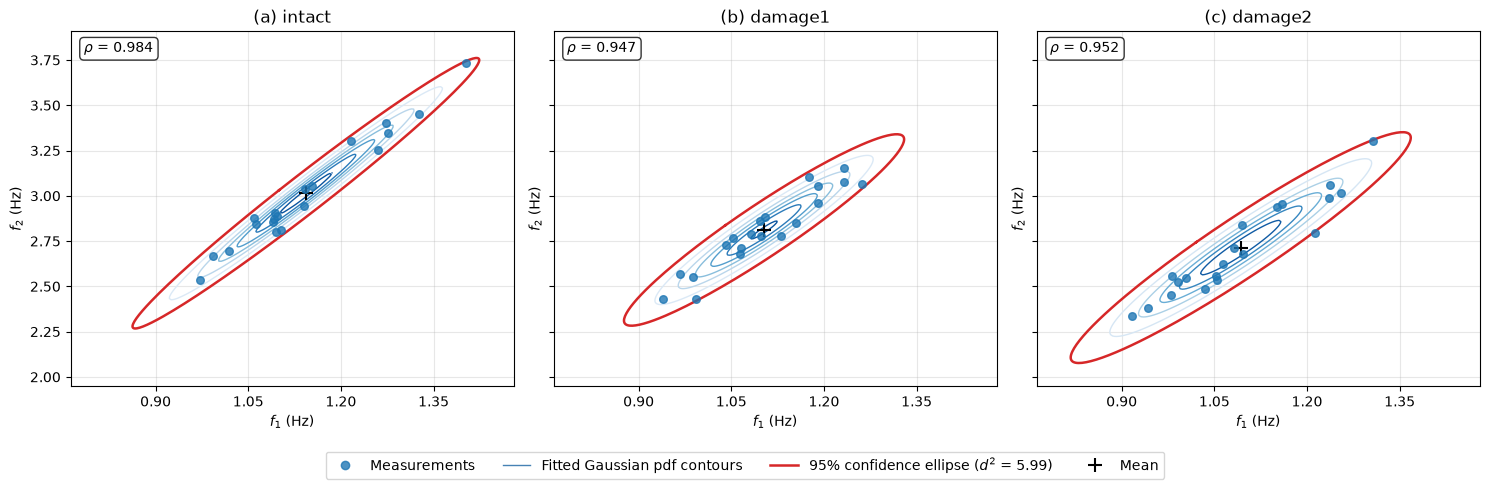

**Figure 11.** Natural frequencies $f_1$ versus $f_2$ with the fitted bivariate Gaussian contours, the 95% confidence ellipse and the correlation coefficient $\rho$ of each scenario: (a) intact, (b) damage1, (c) damage2.

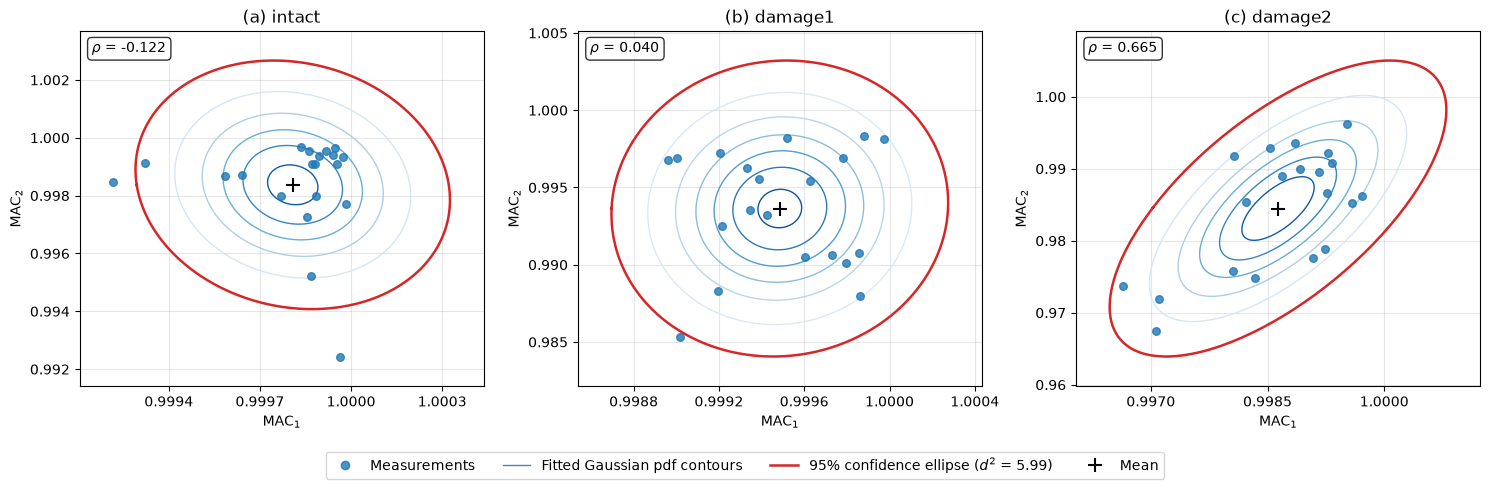

**Figure 12.** $\mathrm{MAC}_1$ versus $\mathrm{MAC}_2$ with the fitted bivariate Gaussian contours, the 95% confidence ellipse and the correlation coefficient $\rho$ of each scenario: (a) intact, (b) damage1, (c) damage2.

In [15]:
# Scatter of each feature pair with the fitted bivariate Gaussian contours, the 95 % ellipse and rho
from matplotlib.lines import Line2D

pair_plots = {
    'f1-f2': {'labels': ('$f_1$ (Hz)', '$f_2$ (Hz)'), 'file': 'C1_f1_f2_gaussian.png',
              'caption': 'Natural frequencies $f_1$ versus $f_2$'},
    'MAC1-MAC2': {'labels': (r'$\mathrm{MAC}_1$', r'$\mathrm{MAC}_2$'), 'file': 'C1_MAC1_MAC2_gaussian.png',
                  'caption': r'$\mathrm{MAC}_1$ versus $\mathrm{MAC}_2$'},
}

for n, (pair, cfg) in enumerate(pair_plots.items(), start=11):
    share = pair == 'f1-f2'                      # frequencies on the same axes; MAC panels scaled to their own data
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=share, sharey=share)
    for ax, sc, label in zip(axes, SCENARIOS, ['(a)', '(b)', '(c)']):
        X, g = pairs[pair][sc], gauss[pair][sc]
        # Grid around the data and the ellipse to evaluate the fitted Gaussian pdf
        pts = np.vstack([X, g['ellipse']])
        lo, hi = pts.min(axis=0), pts.max(axis=0)
        pad = 0.1 * (hi - lo)
        gx, gy = np.meshgrid(np.linspace(lo[0] - pad[0], hi[0] + pad[0], 200),
                             np.linspace(lo[1] - pad[1], hi[1] + pad[1], 200))
        pdf = stats.multivariate_normal(g['mu'], g['cov']).pdf(np.dstack([gx, gy]))
        ax.contour(gx, gy, pdf, levels=6, cmap='Blues', linewidths=1)
        ax.scatter(X[:, 0], X[:, 1], s=30, alpha=0.8, color='tab:blue', zorder=3)
        ax.plot(*g['ellipse'].T, color='tab:red', lw=1.8)
        ax.plot(*g['mu'], 'k+', ms=10, mew=1.5)
        ax.text(0.03, 0.97, rf'$\rho$ = {g["rho"]:.3f}', transform=ax.transAxes, va='top',
                bbox=dict(boxstyle='round', fc='white', alpha=0.8))
        ax.set_title(f'{label} {sc}')
        ax.set_xlabel(cfg['labels'][0])
        ax.set_ylabel(cfg['labels'][1])
        ax.xaxis.set_major_locator(plt.MaxNLocator(5))
        ax.ticklabel_format(useOffset=False)      # show the actual values, not an offset (+1)
        ax.grid(alpha=0.3)
    handles = [Line2D([], [], ls='', marker='o', color='tab:blue', alpha=0.8, label='Measurements'),
               Line2D([], [], color='steelblue', lw=1, label='Fitted Gaussian pdf contours'),
               Line2D([], [], color='tab:red', lw=1.8, label=r'95% confidence ellipse ($d^2$ = 5.99)'),
               Line2D([], [], ls='', marker='+', color='k', ms=10, mew=1.5, label='Mean')]
    fig.tight_layout()
    fig.legend(handles=handles, loc='upper center', ncol=4, bbox_to_anchor=(0.5, 0.0))
    show_figure(fig, n, f'{cfg["caption"]} with the fitted bivariate Gaussian contours, the 95% confidence ellipse '
                r'and the correlation coefficient $\rho$ of each scenario: (a) intact, (b) damage1, (c) damage2.',
                'part-c', cfg['file'])


The natural frequencies are indeed correlated, as shown by the shape of the data cloud in the $f_1$ vs $f_2$ plot and by the correlation coefficient. Physically, this is explained because the scatter of the natural frequency measurements depends mainly on two things: global changes in the stiffness or mass of the bridge (due to changes in temperature or traffic) and the identification errors of each mode. The correlation measures the weight of the common variation of the two variables with respect to their total variation. In this case, a global change in the stiffness or mass of the bridge has a greater impact than the identification errors and shifts the natural frequencies of all the modes in the same direction. That is why the correlation coefficient is close to 1.

On the other hand, the mode shapes are sensitive mainly to changes in the stiffness distribution, not to its total magnitude. Under local damage, this distribution changes, and that is why in Figure 12 the centroid of the data cloud shifts below 1 for both $\text{MAC}_1$ and $\text{MAC}_2$. In contrast, global changes in stiffness or mass do not alter that distribution, so they have almost no influence on the scatter of the MAC values within each scenario. This scatter depends mainly on the identification errors, which are independent for each vibration mode; that is why the MAC values are not correlated with each other.

The correlation of 0.665 obtained for the MAC values of damage 2 is largely influenced by the three points in the lower left corner. These measurements should be analyzed in detail, because they do not correspond to the behavior expected from the previous analysis.

It is important to note that the MAC values have a physical limit of 1 and that all the calculated ellipses exceed that limit, which indicates that the Gaussian distribution is not entirely appropriate for analyzing these variables.

### C2. Mahalanobis Distance Detection (8 pts)

To identify possible anomalies for each feature pair and each damage scenario, the Mahalanobis distance is calculated with the following equation:

$$D = \sqrt{(\mathbf{x}-\boldsymbol{\mu}_0)^{T}\,\boldsymbol{\Sigma}_0^{-1}\,(\mathbf{x}-\boldsymbol{\mu}_0)} \tag{5}$$

- $\mathbf{x}$: the vector with the features of each feature pair in the damage scenarios.
- $\boldsymbol{\mu}_0$: the vector with the mean of each feature of the healthy baseline.
- $\boldsymbol{\Sigma}_0^{-1}$: the inverse of the covariance matrix of the baseline.

and it is compared with the threshold calculated for the intact scenario with 95% confidence ($D_M \approx 2.45$).

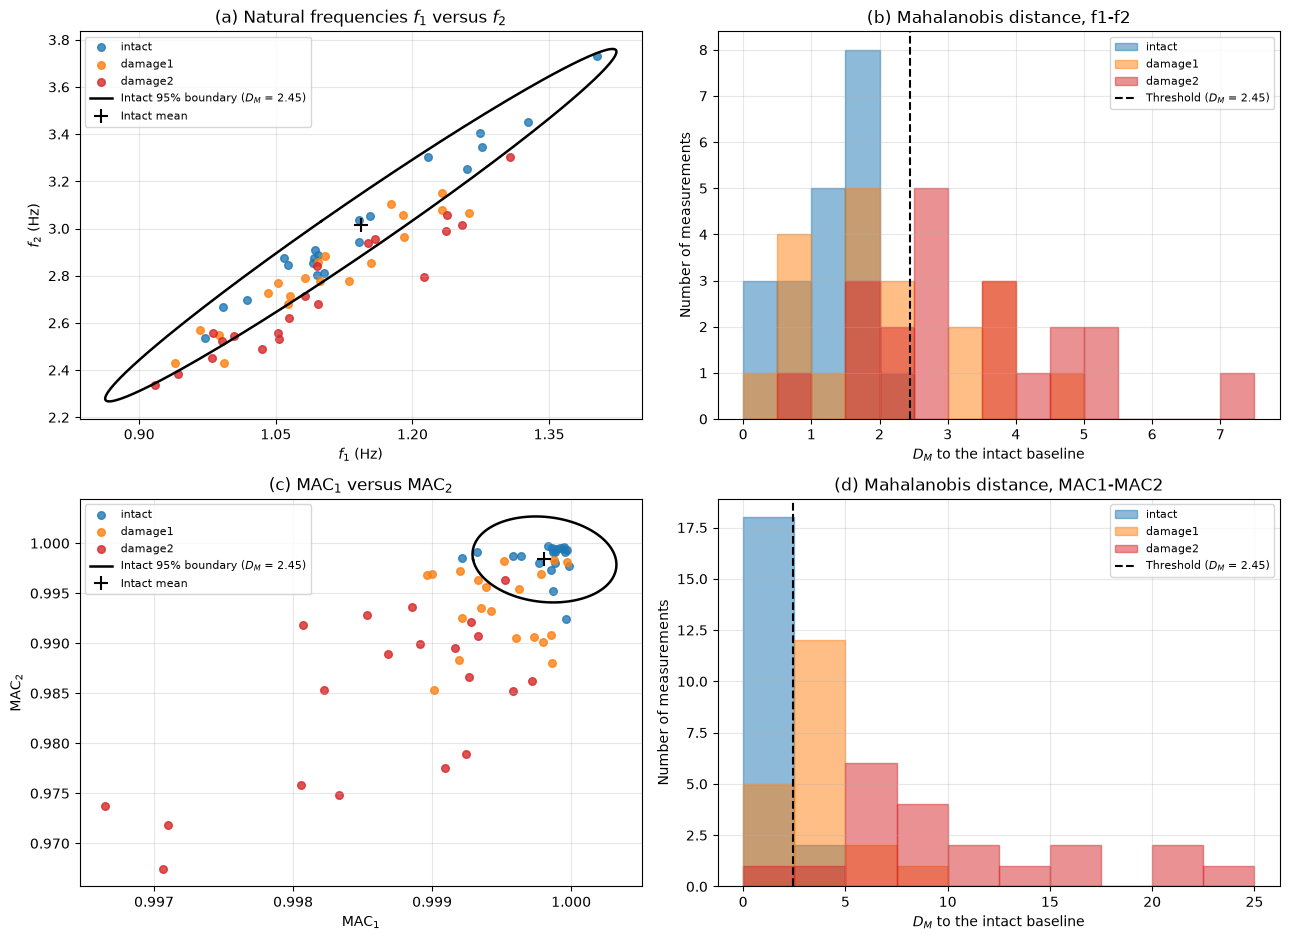

**Figure 13.** Mahalanobis distance detection with the intact scenario as baseline: (a) $f_1$ versus $f_2$ and (c) $\mathrm{MAC}_1$ versus $\mathrm{MAC}_2$ of the 20 measurements of each scenario with the intact 95% boundary; (b) and (d) histograms of the Mahalanobis distance $D_M$ of each measurement to the intact mean, with the 95% threshold.

In [16]:
# Mahalanobis distance of every measurement to the intact baseline (mean and covariance of the intact scenario)
D_THRESHOLD = np.sqrt(CHI2_95)                   # 2.448: distance on the 95 % intact ellipse

def mahalanobis(X, mu, cov):
    d = X - mu                                   # (n, 2) deviations from the baseline mean
    return np.sqrt(np.einsum('ij,jk,ik->i', d, np.linalg.inv(cov), d))


# dm[pair][scenario]: (N_MEAS,) distance of each measurement to the intact mean
dm = {pair: {sc: mahalanobis(X[sc], gauss[pair]['intact']['mu'], gauss[pair]['intact']['cov'])
             for sc in SCENARIOS}
      for pair, X in pairs.items()}


# Rows: feature pairs. Left: measurements and intact 95 % boundary. Right: histogram of D_M per scenario
colors = dict(zip(SCENARIOS, ['tab:blue', 'tab:orange', 'tab:red']))
BIN_WIDTH = {'f1-f2': 0.5, 'MAC1-MAC2': 2.5}       # width of each D_M range in the histograms
fig, axes = plt.subplots(2, 2, figsize=(13, 9.5))
for row, (pair, cfg) in enumerate(pair_plots.items()):
    ax_sc, ax_h = axes[row]
    g0 = gauss[pair]['intact']
    for sc in SCENARIOS:
        ax_sc.scatter(*pairs[pair][sc].T, s=30, alpha=0.8, color=colors[sc], label=sc)
    ax_sc.plot(*g0['ellipse'].T, color='k', lw=1.8, label=rf'Intact 95% boundary ($D_M$ = {D_THRESHOLD:.2f})')
    ax_sc.plot(*g0['mu'], 'k+', ms=10, mew=1.5, label='Intact mean')
    ax_sc.set_title(f'({"ac"[row]}) {cfg["caption"]}')
    ax_sc.set_xlabel(cfg['labels'][0])
    ax_sc.set_ylabel(cfg['labels'][1])
    ax_sc.xaxis.set_major_locator(plt.MaxNLocator(5))
    ax_sc.ticklabel_format(useOffset=False)
    ax_sc.grid(alpha=0.3)
    ax_sc.legend(fontsize=8)

    d_max = max(dm[pair][sc].max() for sc in SCENARIOS)
    bins = np.arange(0, d_max + BIN_WIDTH[pair], BIN_WIDTH[pair])
    for sc in SCENARIOS:
        ax_h.hist(dm[pair][sc], bins=bins, alpha=0.5, color=colors[sc], edgecolor=colors[sc], label=sc)
    ax_h.axvline(D_THRESHOLD, color='k', ls='--', lw=1.5, label=f'Threshold ($D_M$ = {D_THRESHOLD:.2f})')
    ax_h.set_title(f'({"bd"[row]}) Mahalanobis distance, {pair}')
    ax_h.set_xlabel('$D_M$ to the intact baseline')
    ax_h.set_ylabel('Number of measurements')
    ax_h.grid(alpha=0.3)
    ax_h.legend(fontsize=8)
fig.tight_layout()
show_figure(fig, 13, 'Mahalanobis distance detection with the intact scenario as baseline: (a) $f_1$ versus $f_2$ and '
            r'(c) $\mathrm{MAC}_1$ versus $\mathrm{MAC}_2$ of the 20 measurements of each scenario with the intact 95% '
            r'boundary; (b) and (d) histograms of the Mahalanobis distance $D_M$ of each measurement to the intact mean, '
            'with the 95% threshold.', 'part-c', 'C2_mahalanobis.png')

To report the results, the percentage of measurements that exceed the threshold is calculated for each feature pair and each scenario:

$$
\text{Rate} = \frac{\text{Number of measurements with } D_M > 2.45}{\text{Total number of measurements in the scenario}} \times 100\% \tag{6}
$$

The same calculation is interpreted differently depending on the scenario:

- **damage1 and damage2:** it is the detection rate, the percentage of the damage that is correctly detected.
- **intact:** it is the false alarm rate, the percentage of the healthy state that is flagged as damaged. With a 95 % threshold, about 5 % is expected.

In [17]:
# Percentage of measurements above the threshold (Eq. 6): false alarms (intact) and detections (damage)
def rate_text(d):
    k, n = (d > D_THRESHOLD).sum(), len(d)  # measurements above the threshold, total measurements
    return f'{100 * k / n:.0f}% ({k}/{n})'


rates = pd.DataFrame({sc: {pair: rate_text(dm[pair][sc]) for pair in dm} for sc in SCENARIOS})
rates.index.name = 'Feature pair'
rates.columns = ['False alarm rate, intact', 'Detection rate, damage1', 'Detection rate, damage2']
show_table(rates, 12, r'Percentage of measurements with $D_M$ above the 95% threshold ($D_M > 2.45$) '
           'for each feature pair and scenario.', 'C2_detection_rates.csv', precision=1)

**Table 12.** Percentage of measurements with $D_M$ above the 95% threshold ($D_M > 2.45$) for each feature pair and scenario.

,"False alarm rate, intact","Detection rate, damage1","Detection rate, damage2"
Feature pair,,,
f1-f2,0% (0/20),30% (6/20),70% (14/20)
MAC1-MAC2,10% (2/20),75% (15/20),95% (19/20)


### C3. Bivariate vs Univariate Comparison (5 pts)

In [18]:
# Univariate z-score results (|z| > 2): measurements flagged out of 20 per scenario
# damage1 and damage2: detection rates of Part B1 (Table 7, detection_summary_df)
# intact (false alarms, not computed in B1): z-scores of the intact measurements with the B1 baseline (mu0, sigma0)
z_flagged = {}
for feat in ['f1', 'f2', 'MAC1', 'MAC2']:
    b1 = detection_summary_df.loc[feat]
    z_intact = (feature_data['intact'][feat] - b1['Baseline Mean (μ0)']) / b1['Baseline Std (σ0)']
    z_flagged[feat] = {'intact': int((np.abs(z_intact) > 2).sum()),
                       **{sc: int(round(b1[f'{sc.capitalize()} Detection Rate (%)'] * N_MEAS / 100))
                          for sc in ['damage1', 'damage2']}}
N_MEAS = 20  # measurements per scenario

# One table per feature pair: individual features (z-score) next to the pair (Mahalanobis, Table 12)
pair_tables = {'f1-f2':     (13, 'natural frequencies', 'C3_comparison_frequencies.csv'),
               'MAC1-MAC2': (14, 'MAC values', 'C3_comparison_MAC.csv')}
for pair, (number, name, filename) in pair_tables.items():
    rows = []
    for feat in pair.split('-'):
        rows.append([feat, 'z-score, |z| > 2']
                    + [f'{100 * z_flagged[feat][sc] / N_MEAS:.0f}% ({z_flagged[feat][sc]}/{N_MEAS})' for sc in SCENARIOS])
    rows.append([pair, r'Mahalanobis, $D_M$ > 2.45'] + list(rates.loc[pair]))
    comparison = pd.DataFrame(rows, columns=['Feature(s)', 'Method'] + list(rates.columns)).set_index('Feature(s)')
    show_table(comparison, number, f'Detection performance of the individual {name} (univariate z-score, Part B) '
               f'versus the {pair} pair (bivariate Mahalanobis distance, Table 12).', filename)


**Table 13.** Detection performance of the individual natural frequencies (univariate z-score, Part B) versus the f1-f2 pair (bivariate Mahalanobis distance, Table 12).

,Method,"False alarm rate, intact","Detection rate, damage1","Detection rate, damage2"
Feature(s),,,,
f1,"z-score, |z| > 2",5% (1/20),0% (0/20),5% (1/20)
f2,"z-score, |z| > 2",5% (1/20),0% (0/20),10% (2/20)
f1-f2,"Mahalanobis, $D_M$ > 2.45",0% (0/20),30% (6/20),70% (14/20)


**Table 14.** Detection performance of the individual MAC values (univariate z-score, Part B) versus the MAC1-MAC2 pair (bivariate Mahalanobis distance, Table 12).

,Method,"False alarm rate, intact","Detection rate, damage1","Detection rate, damage2"
Feature(s),,,,
MAC1,"z-score, |z| > 2",10% (2/20),45% (9/20),85% (17/20)
MAC2,"z-score, |z| > 2",5% (1/20),50% (10/20),95% (19/20)
MAC1-MAC2,"Mahalanobis, $D_M$ > 2.45",10% (2/20),75% (15/20),95% (19/20)


When two variables are correlated, the bivariate analysis is more effective at detecting shifts in most directions, especially against the correlation, because it takes into account the joint density of the two variables through the Mahalanobis distance. In this way, a data point that shifts against the correlation, or in which only one of the variables moves, is much rarer than if each variable is analyzed separately. If they are analyzed separately, each variable can shift a distance that does not necessarily exceed the 95 % threshold, but the bivariate distribution gives a greater weight to that variation when it does not follow the correlation of the healthy data.

On the contrary, when the two variables shift in the same direction as their correlation, the bivariate analysis gives them a smaller weight, because that behavior is normal in the healthy data. This happens with global changes, such as temperature or traffic mass, which change the stiffness or mass of the whole bridge and shift the frequencies of all the modes in the same proportion.

However, the goal is to detect anomalies caused by damage, not by changes in temperature or mass. When damage occurs, the damage is local and, although it reduces the total stiffness of the bridge, each mode is affected in a different proportion. Therefore, the relationship between the natural frequencies of each mode changes, and the measurement shifts in a direction different from the correlation of the intact state. That is the case in which the bivariate analysis is much more effective than analyzing the variables separately.

In the case of the MAC values, despite not being correlated, the bivariate analysis is still more effective, because it adds up the evidence of the two variables: two moderate deviations that do not exceed the threshold separately can exceed it when they are analyzed together. The only thing is that, for the MAC values, that contour may not really represent the 95 % percentile, but a different percentage. But it is still effective for anomaly detection compared with detection using the variables separately.

The results confirm the above. For the natural frequencies, the separate analysis practically does not detect the damage: $f_1$ and $f_2$ detect 0 % in damage 1 and between 5 % and 10 % in damage 2. In contrast, the pair $(f_1, f_2)$ with the Mahalanobis distance detects 30 % and 70 %, respectively, with no false alarms in the intact state. This indicates that, although part of the shift occurs in the direction of the correlation, the damage does move the measurements out of that direction. For the MAC values, the bivariate analysis raises the detection of damage 1 from 45–50 % to 75 %, and in damage 2 it matches the best individual variable (95 %), with the same false alarm rate as $\mathrm{MAC}_1$ (10 %). Therefore, taking the correlation into account does improve detection.

Between the two pairs, the MAC values are more effective for damage detection, with rates of 75 % and 95 % compared with 30 % and 70 % for the frequencies. This is because local damage changes the stiffness distribution, which is exactly what the mode shapes measure, while the frequencies also change with temperature and mass. However, the MAC pair has a false alarm rate of 10 % in the intact state, higher than the expected 5 %, which is consistent with the Gaussian distribution not being entirely appropriate for these variables.

<a id="part-d"></a>
## Part D: Feature Fusion and Engineering (15 pts)

### D1. Systematic Combination Testing (10 pts)

The dictionary `features` is created with the matrices of the 6 features for each scenario (3 scenarios x 20 samples x 6 features).

In [19]:
# All six features in one matrix per scenario: [f1, f2, f3, MAC1, MAC2, MAC3]
FEATURES = ['f1', 'f2', 'f3', 'MAC1', 'MAC2', 'MAC3']

# features[scenario]: (N_MEAS, 6) array -> measurements x features (MAC of the three modes from Part A3)
features = {sc: np.column_stack([freqs[sc], mac_results[sc]]) for sc in SCENARIOS}

The values are standardized using the measurements of the intact scenario as the baseline, with the following equation:

$$z_{ij} = \frac{x_{ij} - \mu_{0,j}}{\sigma_{0,j}} \tag{7}$$

where:
- $x_{ij}$: value of feature $j$ in measurement $i$ (of any scenario).
- $\mu_{0,j}$: mean of feature $j$ in the intact scenario.
- $\sigma_{0,j}$: sample standard deviation (ddof = 1) of feature $j$ in the intact scenario.
- $z_{ij}$: standardized value.

In [20]:
# Step 1: mean and standard deviation of each feature in the intact scenario (baseline)
mu0 = features['intact'].mean(axis=0)            # (6,) mean of each feature
sigma0 = features['intact'].std(axis=0, ddof=1)  # (6,) sample standard deviation of each feature

baseline_table = pd.DataFrame({'Mean': mu0, 'Standard deviation': sigma0},
                              index=pd.Index(FEATURES, name='Feature'))
show_table(baseline_table, 15, 'Mean and standard deviation of each feature in the intact scenario '
           '(baseline used for the standardization).', 'D1_intact_baseline.csv', precision=6)

**Table 15.** Mean and standard deviation of each feature in the intact scenario (baseline used for the standardization).

,Mean,Standard deviation
Feature,,
f1,1.143267,0.114653
f2,3.014206,0.305121
f3,4.347781,0.448803
MAC1,0.999808,0.000211
MAC2,0.998374,0.001756
MAC3,0.998017,0.001389


In [21]:
# Step 2: standardize every scenario with the intact statistics: z = (x - mu0) / sigma0
features_std = {sc: (features[sc] - mu0) / sigma0 for sc in SCENARIOS}

# Check: the standardized intact features must have mean 0 and standard deviation 1
assert np.allclose(features_std['intact'].mean(axis=0), 0)
assert np.allclose(features_std['intact'].std(axis=0, ddof=1), 1)
for sc in SCENARIOS:
    print(f'{sc}: mean = {np.round(features_std[sc].mean(axis=0), 2)}, '
          f'std = {np.round(features_std[sc].std(axis=0, ddof=1), 2)}')

intact: mean = [-0. -0. -0. -0.  0. -0.], std = [1. 1. 1. 1. 1. 1.]
damage1: mean = [-0.35 -0.66 -0.35 -1.52 -2.7  -3.15], std = [0.81 0.71 0.74 1.53 2.23 2.82]
damage2: mean = [ -0.44  -0.98  -0.4   -5.55  -7.92 -10.74], std = [0.98 0.85 0.83 4.18 4.78 6.43]


All the possible combinations of 4 out of the 6 features are generated, and the Wasserstein distance is calculated for both damage scenario 1 and damage scenario 2, using the intact scenario as the reference.

In [22]:
# All ways to select 4 of the 6 features: C(6, 4) = 15 combinations (column indices in features_std)
from itertools import combinations

combos = list(combinations(range(len(FEATURES)), 4))
combo_names = [', '.join(FEATURES[j] for j in c) for c in combos]   # e.g. 'f1, f2, f3, MAC1'
assert len(combos) == 15

# Multivariate Wasserstein distance between intact and each damage scenario, for each 4-feature combination
DAMAGES = ['damage1', 'damage2']

# w_combo[damage]: (15,) distance of each combination, computed on the standardized features
w_combo = {dmg: np.array([stats.wasserstein_distance_nd(features_std['intact'][:, list(c)],
                                                        features_std[dmg][:, list(c)])
                          for c in combos])
           for dmg in DAMAGES}

w_combo_table = pd.DataFrame({'Features': combo_names,
                              **{f'W (intact, {dmg})': w_combo[dmg] for dmg in DAMAGES}},
                             index=pd.RangeIndex(1, len(combos) + 1, name='Combination'))
show_table(w_combo_table, 16, 'Multivariate Wasserstein distance between the intact scenario and each damage '
           'scenario for the 15 combinations of 4 standardized features.', 'D1_wasserstein_combinations.csv',
           precision=3)

**Table 16.** Multivariate Wasserstein distance between the intact scenario and each damage scenario for the 15 combinations of 4 standardized features.

,Features,"W (intact, damage1)","W (intact, damage2)"
Combination,,,
1,"f1, f2, f3, MAC1",1.872,5.704
2,"f1, f2, f3, MAC2",2.903,8.024
3,"f1, f2, f3, MAC3",3.335,10.822
4,"f1, f2, MAC1, MAC2",3.417,9.925
5,"f1, f2, MAC1, MAC3",3.801,12.382
6,"f1, f2, MAC2, MAC3",4.291,13.432
7,"f1, f3, MAC1, MAC2",3.362,9.886
8,"f1, f3, MAC1, MAC3",3.751,12.348
9,"f1, f3, MAC2, MAC3",4.242,13.400


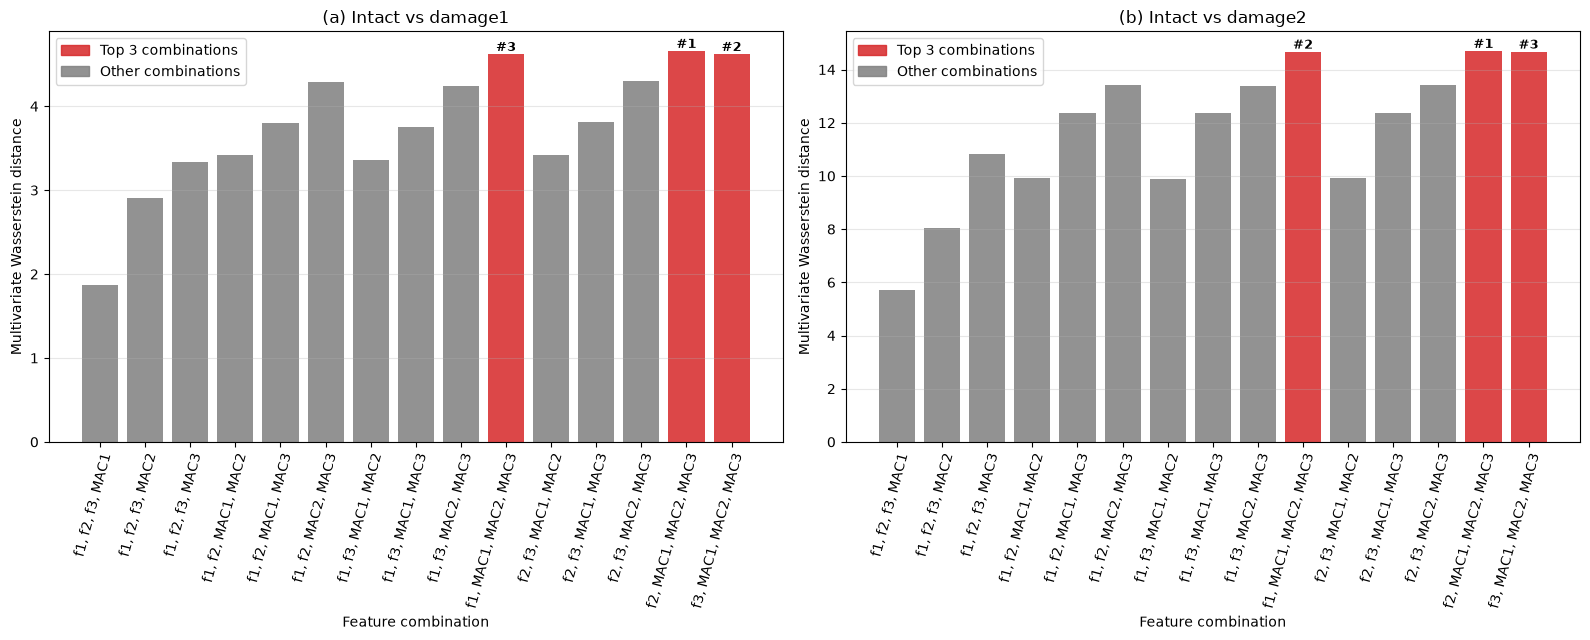

**Figure 14.** Multivariate Wasserstein distance between the intact scenario and (a) damage1, (b) damage2 for the 15 combinations of 4 standardized features. The 3 most sensitive combinations of each scenario are highlighted and ranked.

In [23]:
# Bar chart of the Wasserstein distance of each combination, one panel per damage scenario; top 3 highlighted
from matplotlib.patches import Patch

top3 = {dmg: np.argsort(w_combo[dmg])[::-1][:3] for dmg in DAMAGES}   # indices of the 3 largest distances

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
x = np.arange(len(combos))
for ax, dmg, label in zip(axes, DAMAGES, ['(a)', '(b)']):
    bar_colors = ['tab:red' if k in top3[dmg] else 'tab:gray' for k in x]
    ax.bar(x, w_combo[dmg], color=bar_colors, alpha=0.85)
    for rank, k in enumerate(top3[dmg], start=1):
        ax.text(k, w_combo[dmg][k], f'#{rank}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    ax.set_xticks(x, combo_names, rotation=75, ha='right', rotation_mode='anchor')
    ax.set_title(f'{label} Intact vs {dmg}')
    ax.set_xlabel('Feature combination')
    ax.set_ylabel('Multivariate Wasserstein distance')
    ax.grid(axis='y', alpha=0.3)
    ax.legend(handles=[Patch(color='tab:red', alpha=0.85, label='Top 3 combinations'),
                       Patch(color='tab:gray', alpha=0.85, label='Other combinations')], loc='upper left')
fig.tight_layout()
show_figure(fig, 14, 'Multivariate Wasserstein distance between the intact scenario and (a) damage1, (b) damage2 for the '
            '15 combinations of 4 standardized features. The 3 most sensitive combinations of each scenario are '
            'highlighted and ranked.', 'part-d', 'D1_wasserstein_combinations.png')

In [24]:
# Top 3 most sensitive combinations (largest Wasserstein distance) for each damage scenario
top3_table = pd.DataFrame(
    {(dmg, col): [val(k) for k in top3[dmg]]
     for dmg in DAMAGES
     for col, val in [('Features', lambda k: combo_names[k]), ('W', lambda k: w_combo[dmg][k])]},
    index=pd.RangeIndex(1, 4, name='Rank'))
show_table(top3_table, 17, 'Top 3 most sensitive combinations of 4 features (largest multivariate Wasserstein '
           'distance to the intact scenario) for each damage scenario.', 'D1_top3_combinations.csv', precision=3)

**Table 17.** Top 3 most sensitive combinations of 4 features (largest multivariate Wasserstein distance to the intact scenario) for each damage scenario.

To compare the detection methods in Part F, the Mahalanobis distance detection of Part C2 (Eq. 5) is also applied to the most sensitive combination of 4 features (Table 17), with the 95 % threshold for 4 features, $D_M > \sqrt{\chi^2_{4,\,0.95}} = 3.08$.

In [25]:
# Mahalanobis distance detection (Eq. 5) with the most sensitive combination of 4 features (Table 17)
assert top3['damage1'][0] == top3['damage2'][0]
best_combo = list(combos[top3['damage1'][0]])     # f2, MAC1, MAC2, MAC3
X_combo = {sc: features_std[sc][:, best_combo] for sc in SCENARIOS}

# Intact baseline of the combination and 95 % threshold for 4 features: sqrt(chi2_0.95(4)) = 3.08
mu0_combo = X_combo['intact'].mean(axis=0)
cov0_combo = np.cov(X_combo['intact'], rowvar=False, ddof=1)
D_THRESHOLD_4D = np.sqrt(stats.chi2.ppf(0.95, df=len(best_combo)))

# dm_combo[scenario]: (N_MEAS,) distance of each measurement to the intact mean
dm_combo = {sc: mahalanobis(X_combo[sc], mu0_combo, cov0_combo) for sc in SCENARIOS}

n_above = {sc: int((dm_combo[sc] > D_THRESHOLD_4D).sum()) for sc in SCENARIOS}
combo_rates = pd.DataFrame([[f'{100 * n_above[sc] / N_MEAS:.0f}% ({n_above[sc]}/{N_MEAS})' for sc in SCENARIOS]],
                           index=pd.Index([combo_names[top3['damage1'][0]]], name='Feature combination'),
                           columns=['False alarm rate, intact', 'Detection rate, damage1', 'Detection rate, damage2'])
show_table(combo_rates, 18, r'Percentage of measurements with $D_M$ above the 95% threshold for 4 features '
           r'($D_M > 3.08$) with the most sensitive combination (Table 17).', 'D1_best_combination_detection.csv')

**Table 18.** Percentage of measurements with $D_M$ above the 95% threshold for 4 features ($D_M > 3.08$) with the most sensitive combination (Table 17).

,"False alarm rate, intact","Detection rate, damage1","Detection rate, damage2"
Feature combination,,,
"f2, MAC1, MAC2, MAC3",5% (1/20),70% (14/20),95% (19/20)


### D2. Feature Importance Analysis (5 pts)

The features that appear most often in the best-performing combinations are the MAC values.

The frequency-dominated combinations have a Wasserstein distance between 1.872 and 3.335 for damage scenario 1 and between 5.704 and 10.822 for damage scenario 2, while the MAC-dominated combinations have a Wasserstein distance of approximately 4.6 for damage scenario 1 and approximately 14.7 for damage scenario 2. This shows that the MAC-dominated combinations are more sensitive to damage than the frequency-dominated ones. This result confirms what was found in Part B2, where the MAC values turned out to be the features most sensitive to damage.

In [26]:
# Normalized Wasserstein distance of each single feature from Part B2 (W1 / sigma0, w1_dict of Table 8)
w1_norm = {dmg: dict(zip(feature_names, w1_dict[dmg])) for dmg in DAMAGES}

# Best 4 single features (Part B2) next to the best 4 combinations of 4 features (D1, Table 16) for each damage
top4_feat = {dmg: sorted(w1_norm[dmg], key=w1_norm[dmg].get, reverse=True)[:4] for dmg in DAMAGES}
top4_combo = {dmg: np.argsort(w_combo[dmg])[::-1][:4] for dmg in DAMAGES}

best_table = pd.DataFrame(
    {(dmg, col): vals
     for dmg in DAMAGES
     for col, vals in [('Feature (B2)', top4_feat[dmg]),
                       ('W1,norm', [w1_norm[dmg][f] for f in top4_feat[dmg]]),
                       ('Combination (D1)', [combo_names[k] for k in top4_combo[dmg]]),
                       ('W', w_combo[dmg][top4_combo[dmg]])]},
    index=pd.RangeIndex(1, 5, name='Rank'))
show_table(best_table, 19, 'Best 4 single features (normalized Wasserstein distance, Part B2) and best 4 combinations of '
           '4 features (multivariate Wasserstein distance, Table 16) for each damage scenario.',
           'D2_best_features_vs_combinations.csv', precision=3)


**Table 19.** Best 4 single features (normalized Wasserstein distance, Part B2) and best 4 combinations of 4 features (multivariate Wasserstein distance, Table 16) for each damage scenario.

From Table 19 it can be seen that the combination of the top 4 features obtained in the Part B analysis is the combination most sensitive to damage for both damage scenarios.

The best combination ($f_2$, $\mathrm{MAC}_1$, $\mathrm{MAC}_2$, $\mathrm{MAC}_3$) has a Wasserstein distance of 4.660 for damage scenario 1 and 14.702 for damage scenario 2, while the best single feature, $\mathrm{MAC}_3$, has 3.227 and 11.022, respectively. This represents an increase of approximately 44 % and 33 %. Since the Wasserstein distance compares how shifted two distributions are, feature fusion does increase the sensitivity to damage. However, part of this increase is only due to adding more dimensions, so this distance indicates a greater separation between the distributions, but not necessarily a better detection of each measurement.

In the case of damage detection, where current distributions are compared with the distributions of the intact scenario or healthy bridge, both the frequencies and the MAC values provide independent information about the damage, because with local damage, the mode shapes and the relationship between the natural frequencies of each vibration mode are affected in different ways.

<a id="part-e"></a>
## Part E: Principal Component Analysis (15 pts)

### E1. PCA Implementation and Variance Analysis (4 pts)

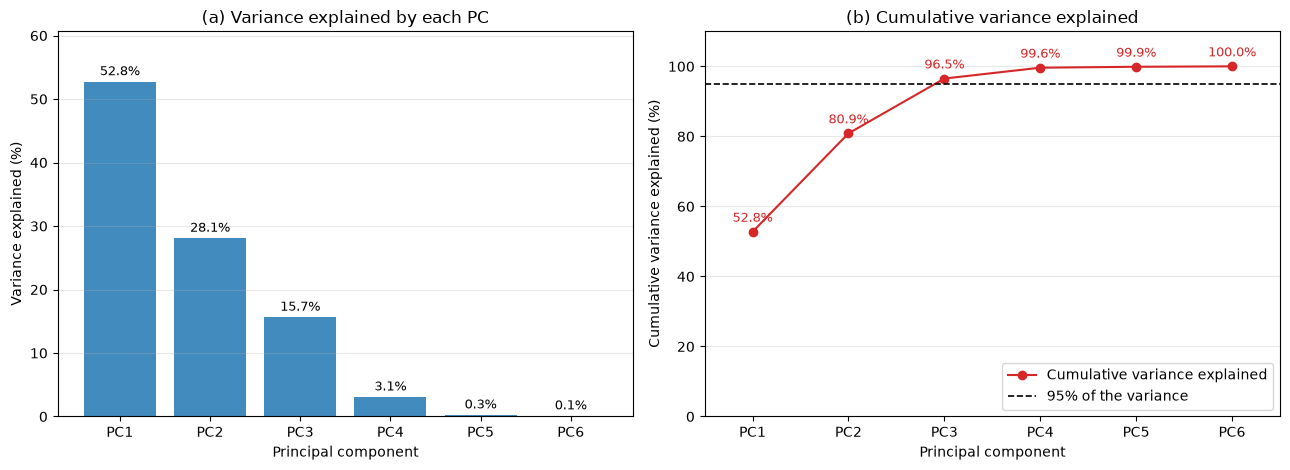

**Figure 15.** Scree plot of the PCA fitted on the 6 standardized features of the intact scenario: (a) variance explained by each principal component and (b) cumulative variance. 3 components are needed to capture 95% of the variance.

In [27]:
# The matrix features_std calculated above is used in this section
from sklearn.decomposition import PCA

# PCA fitted on the standardized intact data only (20 x 6); all 6 components are kept
pca = PCA(n_components=len(FEATURES))
pca.fit(features_std['intact'])

# Scree plot: variance explained by each PC (bars) and cumulative variance (line), with the 95 % level
var_pct = 100 * pca.explained_variance_ratio_
cum_pct = np.cumsum(var_pct)
pcs = np.arange(1, len(var_pct) + 1)
k95 = np.argmax(cum_pct >= 95) + 1               # number of PCs needed to reach 95 % of the variance

# (a) variance explained by each PC, (b) cumulative variance explained with the 95 % level
fig, (ax_a, ax_b) = plt.subplots(1, 2, figsize=(13, 4.8))
ax_a.bar(pcs, var_pct, color='tab:blue', alpha=0.85)
for p, v in zip(pcs, var_pct):
    ax_a.text(p, v + 1, f'{v:.1f}%', ha='center', fontsize=9)
ax_a.set_ylim(0, 1.15 * var_pct.max())
ax_a.set_title('(a) Variance explained by each PC')
ax_a.set_ylabel('Variance explained (%)')

ax_b.plot(pcs, cum_pct, 'o-', color='tab:red', label='Cumulative variance explained')
ax_b.axhline(95, color='k', ls='--', lw=1.2, label='95% of the variance')
for p, c in zip(pcs, cum_pct):
    ax_b.text(p, c + 2, f'{c:.1f}%', ha='center', va='bottom', fontsize=9, color='tab:red')
ax_b.set_ylim(0, 110)
ax_b.set_xlim(0.5, len(pcs) + 0.5)
ax_b.set_title('(b) Cumulative variance explained')
ax_b.set_ylabel('Cumulative variance explained (%)')
ax_b.legend(loc='lower right')

for ax in (ax_a, ax_b):
    ax.set_xticks(pcs, [f'PC{p}' for p in pcs])
    ax.set_xlabel('Principal component')
    ax.grid(axis='y', alpha=0.3)
fig.tight_layout()
show_figure(fig, 15, 'Scree plot of the PCA fitted on the 6 standardized features of the intact scenario: (a) variance '
            f'explained by each principal component and (b) cumulative variance. {k95} components are needed to capture '
            '95% of the variance.', 'part-e', 'E1_scree_plot.png')

As can be seen in Figure 15, at least the first 3 components are needed to represent 95% of the variance of the data.

### E2. First Principal Component Analysis (3 pts)

The data of the 6 variables are projected onto PCA component 1 for each of the scenarios.

In [28]:
# Project the standardized features of every scenario onto PC1 only (PCA fitted on the intact data)
# pc1[scenario]: (N_MEAS,) score of each measurement on the first principal component
pc1 = {sc: pca.transform(features_std[sc])[:, 0] for sc in SCENARIOS}

for sc in SCENARIOS:
    print(f'{sc}: {pc1[sc].shape[0]} PC1 scores, mean = {pc1[sc].mean():.3f}, std = {pc1[sc].std(ddof=1):.3f}')

intact: 20 PC1 scores, mean = 0.000, std = 1.779
damage1: 20 PC1 scores, mean = 0.231, std = 1.503
damage2: 20 PC1 scores, mean = 1.970, std = 2.512


It is important to note that, although the data were standardized with the intact scenario ($\mu = 0$ and $\sigma = 1$ for each feature), the total variance is 6, that is, the sum of the variances of the six features. Since PCA component 1 represents 52.8 % of that total variance, its variance is $0.528 \times 6 \approx 3.17$ and its standard deviation is $\sqrt{3.17} \approx 1.78$. That is why the standard deviation of PC1 is greater than 1: it concentrates the variation shared by the correlated features.

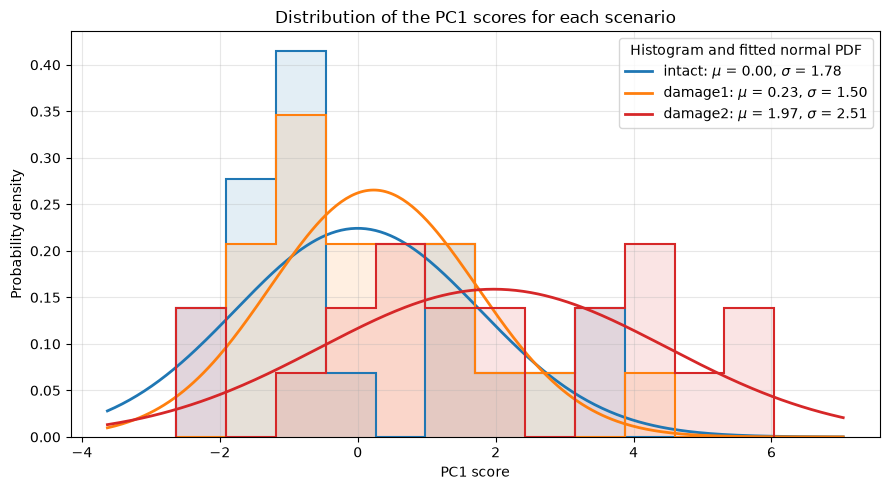

**Figure 16.** Overlaid histograms of the PC1 scores of the intact, damage1 and damage2 scenarios, with the normal PDF fitted to each scenario (mean $\mu$ and standard deviation $\sigma$ in the legend). PCA fitted on the standardized intact data.

In [29]:
# Overlaid histograms of the PC1 scores of the three scenarios, each with its fitted normal PDF
all_pc1 = np.concatenate([pc1[sc] for sc in SCENARIOS])
bins = np.linspace(all_pc1.min(), all_pc1.max(), 13)   # same bins for the three scenarios
x_pdf = np.linspace(all_pc1.min() - 1, all_pc1.max() + 1, 300)

fig, ax = plt.subplots(figsize=(9, 5))
for sc in SCENARIOS:
    mu, sd = pc1[sc].mean(), pc1[sc].std(ddof=1)
    ax.hist(pc1[sc], bins=bins, density=True, alpha=0.12, color=colors[sc])
    ax.hist(pc1[sc], bins=bins, density=True, histtype='step', lw=1.5, color=colors[sc])
    ax.plot(x_pdf, stats.norm.pdf(x_pdf, mu, sd), color=colors[sc], lw=2,
            label=rf'{sc}: $\mu$ = {mu:.2f}, $\sigma$ = {sd:.2f}')
ax.set_title('Distribution of the PC1 scores for each scenario')
ax.set_xlabel('PC1 score')
ax.set_ylabel('Probability density')
ax.grid(alpha=0.3)
ax.legend(title='Histogram and fitted normal PDF')
fig.tight_layout()
show_figure(fig, 16, 'Overlaid histograms of the PC1 scores of the intact, damage1 and damage2 scenarios, with the normal '
            r'PDF fitted to each scenario (mean $\mu$ and standard deviation $\sigma$ in the legend). PCA fitted on the '
            'standardized intact data.', 'part-e', 'E2_PC1_distributions.png')

In [30]:
# 1D Wasserstein distance between the PC1 scores of the intact scenario and each damage scenario
w_pc1 = {dmg: stats.wasserstein_distance(pc1['intact'], pc1[dmg]) for dmg in DAMAGES}

# Normalized as in Part B2 (W1 / sigma0): divide by the standard deviation of the intact PC1 scores
sigma0_pc1 = pc1['intact'].std(ddof=1)
w_pc1_norm = {dmg: w_pc1[dmg] / sigma0_pc1 for dmg in DAMAGES}

w_pc1_table = pd.DataFrame({f'W1,norm (intact, {dmg})': [w_pc1_norm[dmg]] for dmg in DAMAGES},
                           index=pd.Index(['PC1'], name='PCA space'))
show_table(w_pc1_table, 20, 'Normalized Wasserstein distance $W_1/\\sigma_0$ between the PC1 scores of the '
           'intact scenario and each damage scenario (same normalization as Part B2).',
           'E2_wasserstein_PC1.csv', precision=3)

**Table 20.** Normalized Wasserstein distance $W_1/\sigma_0$ between the PC1 scores of the intact scenario and each damage scenario (same normalization as Part B2).

,"W1,norm (intact, damage1)","W1,norm (intact, damage2)"
PCA space,,
PC1,0.269,1.107


The Wasserstein distance of PC1, normalized with respect to the intact scenario, is lower than that of all the individual features in damage scenario 1, and in damage scenario 2 it only exceeds the natural frequencies, staying far below the MAC values. This is mainly because PC1 keeps the direction in which the data of the intact scenario vary the most, which is that of the natural frequencies, because changes in temperature and mass shift them together. That direction is the least useful for detecting damage, while the change in the MAC values remains in other components. That is why, although PC1 represents 52.8 % of the variance, the most important information about the damage is being lost.

### E3. Two-Dimensional PCA Space (3 pts)

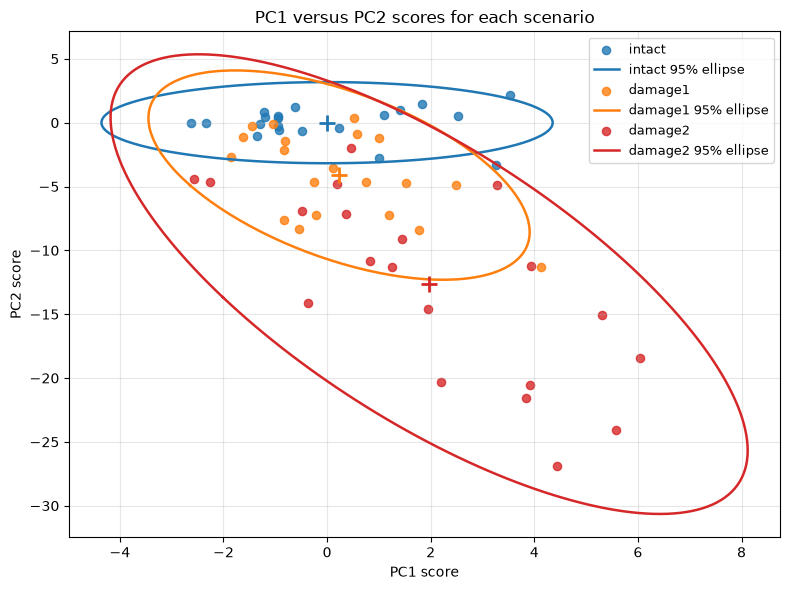

**Figure 17.** Scores of the 20 measurements of each scenario on the first two principal components (PC1 versus PC2), with the 95% confidence ellipse of the bivariate Gaussian fitted to each scenario (+: mean). PCA fitted on the standardized intact data.

In [31]:
# Project the standardized features of every scenario onto PC1 and PC2 (PCA fitted on the intact data)
# pc12[scenario]: (N_MEAS, 2) array -> measurements x [PC1, PC2]
pc12 = {sc: pca.transform(features_std[sc])[:, :2] for sc in SCENARIOS}

# Bivariate Gaussian fitted to the PC1-PC2 scores of each scenario and its 95 % contour (gaussian_contour from C1)
gauss_pc = {sc: gaussian_contour(pc12[sc]) for sc in SCENARIOS}

# Scatter of PC1 versus PC2 with the 95 % ellipse and the mean of each scenario
fig, ax = plt.subplots(figsize=(8, 6))
for sc in SCENARIOS:
    ax.scatter(*pc12[sc].T, s=35, alpha=0.8, color=colors[sc], label=sc)
    ax.plot(*gauss_pc[sc]['ellipse'].T, color=colors[sc], lw=1.8, label=f'{sc} 95% ellipse')
    ax.plot(*gauss_pc[sc]['mu'], '+', color=colors[sc], ms=12, mew=2)
ax.set_title('PC1 versus PC2 scores for each scenario')
ax.set_xlabel('PC1 score')
ax.set_ylabel('PC2 score')
ax.grid(alpha=0.3)
ax.legend(fontsize=9)
fig.tight_layout()
show_figure(fig, 17, 'Scores of the 20 measurements of each scenario on the first two principal components (PC1 versus '
            'PC2), with the 95% confidence ellipse of the bivariate Gaussian fitted to each scenario (+: mean). '
            'PCA fitted on the standardized intact data.', 'part-e', 'E3_PC1_PC2_scatter.png')

It is verified that the correlation coefficient between PC1 and PC2 in the intact scenario is zero. This is expected, because the PCA was fitted with the data of that scenario and its components, by construction, have zero covariance with each other, that is, they are uncorrelated.

In [32]:
# Correlation coefficient between PC1 and PC2 for the intact data (must be 0: fundamental PCA property)
rho_pc12 = np.corrcoef(pc12['intact'][:, 0], pc12['intact'][:, 1])[0, 1]
print(f'Correlation coefficient between PC1 and PC2 (intact): rho = {rho_pc12:.2e}')

Correlation coefficient between PC1 and PC2 (intact): rho = 3.67e-17


In [33]:
# 2D Wasserstein distance between the PC1-PC2 scores of the intact scenario and each damage scenario
w_pc12 = {dmg: stats.wasserstein_distance_nd(pc12['intact'], pc12[dmg]) for dmg in DAMAGES}

w_pc12_table = pd.DataFrame({f'W (intact, {dmg})': [w_pc12[dmg]] for dmg in DAMAGES},
                            index=pd.Index(['PC1-PC2'], name='PCA space'))
show_table(w_pc12_table, 21, 'Two-dimensional Wasserstein distance between the PC1-PC2 scores of the intact scenario '
           'and each damage scenario.', 'E3_wasserstein_PC1_PC2.csv', precision=3)

**Table 21.** Two-dimensional Wasserstein distance between the PC1-PC2 scores of the intact scenario and each damage scenario.

,"W (intact, damage1)","W (intact, damage2)"
PCA space,,
PC1-PC2,4.175,12.809


Adding the PC2 component significantly increases the sensitivity to damage (from 0.479 to 4.175 in damage 1 and from 1.970 to 12.809 in damage 2). This suggests that PC1 mainly keeps the information given by the natural frequencies and PC2 the information given by the variation of the MAC values. Although the Wasserstein distance increases as variables or dimensions are added, the increase observed when adding PC2 is not explained only by the increase in dimensions.

To compare the detection methods in Part F, the Mahalanobis distance detection of Part C2 (Eq. 5) is also applied to the PC1–PC2 scores, with the same 95 % threshold for 2 dimensions ($D_M > 2.45$).

In [34]:
# Mahalanobis distance detection (Eq. 5) in the PC1-PC2 space, with the intact baseline of gauss_pc
# dm_pc12[scenario]: (N_MEAS,) distance of each measurement to the intact mean
dm_pc12 = {sc: mahalanobis(pc12[sc], gauss_pc['intact']['mu'], gauss_pc['intact']['cov']) for sc in SCENARIOS}

pc12_rates = pd.DataFrame([[rate_text(dm_pc12[sc]) for sc in SCENARIOS]],
                          index=pd.Index(['PC1-PC2'], name='PCA space'),
                          columns=['False alarm rate, intact', 'Detection rate, damage1', 'Detection rate, damage2'])
show_table(pc12_rates, 22, r'Percentage of measurements with $D_M$ above the 95% threshold ($D_M > 2.45$) '
           'in the PC1-PC2 space.', 'E3_PC1_PC2_detection.csv')

**Table 22.** Percentage of measurements with $D_M$ above the 95% threshold ($D_M > 2.45$) in the PC1-PC2 space.

,"False alarm rate, intact","Detection rate, damage1","Detection rate, damage2"
PCA space,,,
PC1-PC2,10% (2/20),55% (11/20),95% (19/20)


### E4. Progressive Dimensionality Impact (3 pts)

In [35]:
# Scores of every scenario on all 6 PCs (PCA fitted on the intact data)
# pc_all[scenario]: (N_MEAS, 6) array -> measurements x [PC1, ..., PC6]
pc_all = {sc: pca.transform(features_std[sc]) for sc in SCENARIOS}

# Wasserstein distance between intact and each damage scenario using the first k PCs, k = 1, ..., 6
K = np.arange(1, len(FEATURES) + 1)
w_k = {dmg: np.array([stats.wasserstein_distance_nd(pc_all['intact'][:, :k], pc_all[dmg][:, :k]) for k in K])
       for dmg in DAMAGES}

w_k_table = pd.DataFrame({f'W (intact, {dmg})': w_k[dmg] for dmg in DAMAGES},
                         index=pd.Index(K, name='Number of PCs k'))
show_table(w_k_table, 23, 'Wasserstein distance between the intact scenario and each damage scenario using the first '
           '$k$ principal components, $k$ = 1, ..., 6.', 'E4_wasserstein_k_PCs.csv', precision=3)

**Table 23.** Wasserstein distance between the intact scenario and each damage scenario using the first $k$ principal components, $k$ = 1, ..., 6.

,"W (intact, damage1)","W (intact, damage2)"
Number of PCs k,,
1,0.479,1.970
2,4.175,12.809
3,4.707,14.601
4,4.750,14.733
5,4.758,14.738
6,4.764,14.742


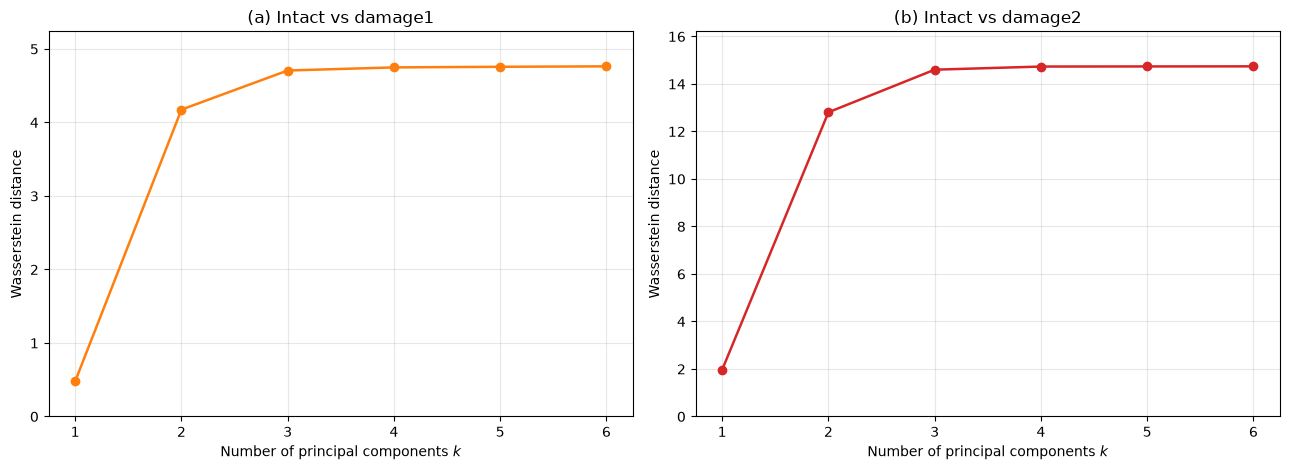

**Figure 18.** Wasserstein distance between the intact scenario and (a) damage1, (b) damage2 as a function of the number of principal components $k$ used (Table 23).

In [36]:
# Wasserstein distance versus the number of PCs k (Table 23), one panel per damage scenario
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, dmg, label in zip(axes, DAMAGES, ['(a)', '(b)']):
    ax.plot(K, w_k[dmg], 'o-', color=colors[dmg], lw=1.8)
    ax.set_xticks(K)
    ax.set_ylim(0, 1.1 * w_k[dmg].max())
    ax.set_title(f'{label} Intact vs {dmg}')
    ax.set_xlabel('Number of principal components $k$')
    ax.set_ylabel('Wasserstein distance')
    ax.grid(alpha=0.3)
fig.tight_layout()
show_figure(fig, 18, 'Wasserstein distance between the intact scenario and (a) damage1, (b) damage2 as a function of the '
            'number of principal components $k$ used (Table 23).', 'part-e', 'E4_wasserstein_k_PCs.png')

With the results of Table 23, it can be said that the sensitivity to damage starts to plateau from k = 3, right where the PCA components represent more than 95% of the variance of the data.

To compare the result of the 6 PCA components with the 6 features without PCA, the Wasserstein distance of the 6 standardized features is calculated for both damage scenarios.

In [37]:
# 6D Wasserstein distance with all standardized features (no PCA), to compare with k = 6 PCs
w_6d = {dmg: stats.wasserstein_distance_nd(features_std['intact'], features_std[dmg]) for dmg in DAMAGES}
for dmg in DAMAGES:
    print(f'{dmg}: 6 features (no PCA) = {w_6d[dmg]:.3f}, 6 PCs = {w_k[dmg][-1]:.3f}')

damage1: 6 features (no PCA) = 4.764, 6 PCs = 4.764
damage2: 6 features (no PCA) = 14.742, 6 PCs = 14.742


As can be seen, the results are identical. This is because the 6 PCA components keep 100 % of the variance of the original data, just along other axes. PCA only rotates the axes of the standardized data, and a rotation does not change the Euclidean distances between the points, so the Wasserstein distance does not change either.

### E5. Physical Interpretation (2 pts)

The PC1 weights (loadings) are obtained from the eigendecomposition (eigenvalues and eigenvectors) of the covariance matrix of the 6 standardized features of the intact scenario:

$$\boldsymbol{\Sigma}_0 = \mathbf{V}\boldsymbol{\Lambda}\mathbf{V}^{T} \tag{8}$$

Where:

- $\boldsymbol{\Sigma}_0$: covariance matrix (6 × 6) of the standardized features of the intact scenario.
- $\mathbf{V}$: matrix whose columns are the eigenvectors; each column defines the direction of a principal component.
- $\boldsymbol{\Lambda}$: diagonal matrix with the eigenvalues, that is, the variance of each component, sorted from largest to smallest.

The PC1 loadings are the 6 values of the first eigenvector, $\mathbf{v}_1 = [v_{11}, \dots, v_{16}]$. In the code, these values correspond to `pca.components_[0]`.

In [38]:
# PC1 loadings: weight of each standardized feature in PC1 (first eigenvector of the intact covariance)
pc1_loadings = pd.DataFrame({'PC1 loading': pca.components_[0]}, index=pd.Index(FEATURES, name='Feature'))
show_table(pc1_loadings, 24, 'Loadings of the first principal component (PCA fitted on the 6 standardized features of '
           'the intact scenario).', 'E5_PC1_loadings.csv', precision=3)


**Table 24.** Loadings of the first principal component (PCA fitted on the 6 standardized features of the intact scenario).

,PC1 loading
Feature,
f1,0.542
f2,0.542
f3,0.544
MAC1,0.163
MAC2,-0.235
MAC3,-0.186


Table 24 shows that the features that contribute most to PC1 are the natural frequencies. This also explains the results obtained in Part E2, where the Wasserstein distances calculated for PC1 were low.

Considering that the variation of the natural frequencies is mainly given by global changes in the stiffness or mass of the structure, it can be said that PC1 physically represents the relationship between the global stiffness and mass of the bridge, that is, the effects of temperature and traffic. Therefore, PC1 mainly represents the environmental and operational variation, not the damage.

According to the results obtained in Section E4, dimensionality reduction works for this type of problem, because the natural frequencies are highly correlated and a single component can represent the variation of all three. That is why 3 components keep 95 % of the variance. The variance discarded by the last components could correspond mainly to errors in the estimation of the features or noise, and since it is variance of the healthy state, discarding it barely changes the sensitivity to damage.

<a id="part-f"></a>
## Part F: Engineering Insights (5 pts)

### F1. Method Comparison and Selection (2 pts)

Rank all detection approaches by effectiveness: single features, bivariate, 4D fusion, PCA

In [39]:
# Best configuration of each detection approach, compared by its false alarm and detection rates with a 95 % threshold
best_feat = top4_feat['damage1'][0]               # most sensitive single feature (Part B2, Table 19): MAC3
best_pair = 'MAC1-MAC2'                           # pair with the higher detection rates (Part C2, Table 12)

# Single feature: damage rates (Table 7) and intact false alarms of Part B1
b1 = detection_summary_df.loc[best_feat]
counts = {'single': {'intact': intact_false_alarms[best_feat],
                     **{sc: int(round(b1[f'{sc.capitalize()} Detection Rate (%)'] * N_MEAS / 100)) for sc in DAMAGES}},
          'bivariate': {sc: int((dm[best_pair][sc] > D_THRESHOLD).sum()) for sc in SCENARIOS},   # Part C2
          'fusion': {sc: int((dm_combo[sc] > D_THRESHOLD_4D).sum()) for sc in SCENARIOS},       # Part D1, Table 18
          'pca': {sc: int((dm_pc12[sc] > D_THRESHOLD).sum()) for sc in SCENARIOS}}               # Part E3, Table 22

approaches = {'single': ('Single feature (B)', best_feat, 1),
              'bivariate': ('Bivariate (C)', best_pair, 2),
              'fusion': ('4D fusion (D)', combo_names[top3['damage1'][0]], 4),
              'pca': ('PCA (E)', 'PC1-PC2', 2)}

method_table = pd.DataFrame(
    {name: {'Best configuration': config, 'Dimensions': dim,
            'False alarm rate, intact': f"{100 * counts[a]['intact'] / N_MEAS:.0f}% ({counts[a]['intact']}/{N_MEAS})",
            **{f'Detection rate, {dmg}': f"{100 * counts[a][dmg] / N_MEAS:.0f}% ({counts[a][dmg]}/{N_MEAS})"
               for dmg in DAMAGES}}
     for a, (name, config, dim) in approaches.items()}).T
method_table.index.name = 'Approach'
show_table(method_table, 25, 'Comparison of the best configuration of each detection approach: false alarm and detection '
           'rates with a 95% threshold (|z| > 2 for one feature, Mahalanobis distance above the chi-square threshold '
           'of its dimension otherwise).',
           'F1_method_comparison.csv')

**Table 25.** Comparison of the best configuration of each detection approach: false alarm and detection rates with a 95% threshold (|z| > 2 for one feature, Mahalanobis distance above the chi-square threshold of its dimension otherwise).

,Best configuration,Dimensions,"False alarm rate, intact","Detection rate, damage1","Detection rate, damage2"
Approach,,,,,
Single feature (B),MAC3,1,10% (2/20),55% (11/20),95% (19/20)
Bivariate (C),MAC1-MAC2,2,10% (2/20),75% (15/20),95% (19/20)
4D fusion (D),"f2, MAC1, MAC2, MAC3",4,5% (1/20),70% (14/20),95% (19/20)
PCA (E),PC1-PC2,2,10% (2/20),55% (11/20),95% (19/20)


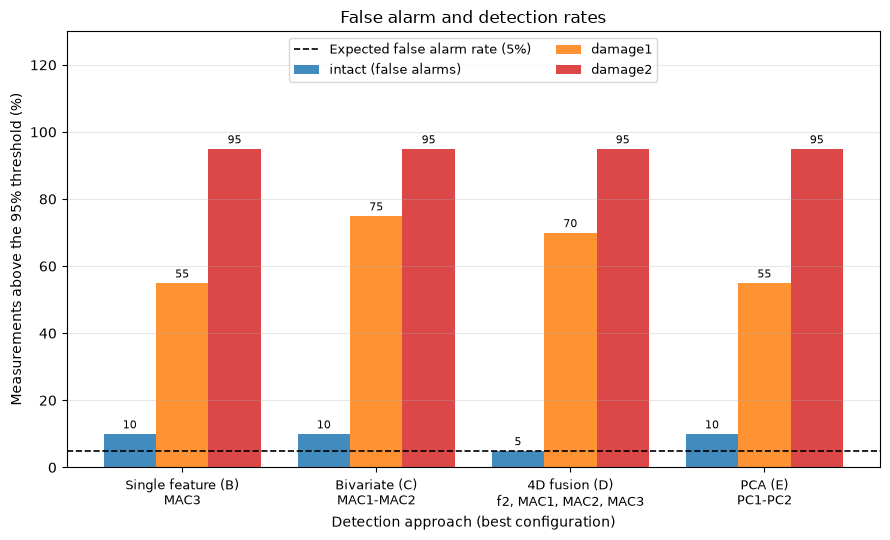

**Figure 19.** Comparison of the best configuration of each detection approach (Table 25): false alarm rate in the intact scenario and detection rates in damage1 and damage2 with a 95% threshold.

In [40]:
# False alarm and detection rates of the best configuration of each approach
labels = [f'{name}\n{config}' for name, config, _ in approaches.values()]
x = np.arange(len(approaches))
fig, ax = plt.subplots(figsize=(9, 5.5))

width = 0.27
for n, sc in enumerate(SCENARIOS):
    rates_sc = [100 * counts[a][sc] / N_MEAS for a in approaches]
    bars = ax.bar(x + (n - 1) * width, rates_sc, width, color=colors[sc], alpha=0.85,
                    label='intact (false alarms)' if sc == 'intact' else sc)
    ax.bar_label(bars, fmt='%.0f', padding=2, fontsize=8)
ax.axhline(5, color='k', ls='--', lw=1.2, label='Expected false alarm rate (5%)')
ax.set_ylim(0, 130)
ax.set_title('False alarm and detection rates')
ax.set_ylabel('Measurements above the 95% threshold (%)')
ax.set_xticks(x, labels, fontsize=9)
ax.set_xlabel('Detection approach (best configuration)')
ax.grid(axis='y', alpha=0.3)
ax.legend(fontsize=9, loc='upper center', ncol=2)
fig.tight_layout()
show_figure(fig, 19, 'Comparison of the best configuration of each detection approach (Table 25): false alarm rate in '
            'the intact scenario and detection rates in damage1 and damage2 with a 95% threshold.', 'part-f',
            'F1_method_comparison.png')

According to the results obtained, the features most sensitive to damage were the MAC values. All the methods applied to the best combinations of features had the same damage detection effectiveness for scenario 2 (95 %). However, the main difference was in the damage detection of scenario 1, where the damage is moderate. For continuous and real-time monitoring, where the main goal is to detect the damage as early as possible, we consider that the most appropriate method is the bivariate one with MAC1-MAC2, which had an effectiveness of 75 % for the moderate damage scenario. In addition, it has the lowest computational cost among the multivariate methods. Despite this, its false alarm rate (10 %) was higher than that of the 4D fusion (5 %), which can be understood as twice as many false alarms or as only 1 more false alarm. In the same way, the difference in the detection of the moderate damage compared with the 4D fusion (75 % versus 70 %) corresponds to only 1 measurement. That is why, for a more precise analysis, it would be important to have many more measurements, since 20 measurements may be too few to represent the real variance of each feature.

### F2. Feature Selection Strategy (2 pts)

If only two features had to be chosen to monitor the health of this bridge, we would recommend using MAC1 and MAC2, because it was the bivariate combination most sensitive to damage and with the best detection rates (75 % for the moderate damage and 95 % for the severe damage).

According to the results obtained in this project, we can say that the MAC values are indeed necessary, especially for early damage detection. The natural frequencies also provide useful information; in fact, the bivariate analysis of f1-f2 detected 30 % of the moderate damage and 70 % of the severe damage, with no false alarms in the intact state. However, the MAC values are more effective at detecting moderate damage.

However, it is important to keep in mind that obtaining the mode shapes of a bridge can be challenging, since it requires suitable equipment, which in turn is expensive and must also be installed on the bridge in a strategic way.

If we had to define a continuous monitoring strategy, in order from least to most complex, it would be first the bivariate analysis of the natural frequencies of modes 1 and 2, and then the bivariate analysis of MAC1 and MAC2. The first level is the simplest, because the frequencies can be identified with few sensors, and it gave no false alarms in the intact state, so an alarm at this level is a reliable sign of damage.

### F3. Practical Implementation Considerations (1 pt)

Temperature changes can cause changes in the stiffness of the bridge and, therefore, shifts in the distribution of the natural frequency measurements. In cities like Edmonton, which experience such harsh winters, low temperatures increase the stiffness of the bridge and its natural frequencies. This can cause the measured frequencies to exceed a threshold that was established using measurements taken in summer or in any other season, without the bridge necessarily being damaged. Or, on the contrary, the bridge may have damage, which decreases the frequencies, and the effect of temperature may hide it. Therefore, when establishing a monitoring strategy for the bridge, it must be taken into account that the distributions of the natural frequencies of a healthy bridge (baseline) can be different from one season to another.

Ideally, continuous measurements of the healthy bridge would be taken for a year to estimate the effect of temperature on the baseline distribution, for example, by establishing a baseline for each temperature range.

Finally, when establishing the detection limits, we consider that it is much better to ensure a better damage detection rate (fewer false negatives), even if more false alarms are generated (false positives). Undetected damage can have serious consequences for the safety of the bridge, while a false alarm only implies an additional analysis or perhaps an inspection.

<a id="ai-note"></a>
## Use of Generative AI

Each group member describes their own use of AI below.

### Amilcar Diaz

**Tool:** Claude Code (Anthropic, Claude Opus model), used inside VS Code.

**How I used it**

- **Code.** To write the Python code for the data extraction (Section 0) and Parts C–E, including figures and tables, following my step-by-step instructions. I reviewed each result before moving on and asked for corrections when needed.
- **Concepts.** To clarify the statistical methods before applying them (Mahalanobis distance, χ² distribution, Gaussian contours, PCA).
- **Writing and organization.** To translate my discussions from Spanish into English, to number figures, tables and equations, and to merge the notebook versions of the group.

**Main prompts** (grouped, originally in Spanish)

- Explanations: "How is [method] calculated, and why does [result] happen?"
- Code: "In section [X], compute [quantity] for each scenario and report it in a table or figure."
- Revisions: "Change [figure or table] so that [...]."
- Translation: "Translate the text into English, keeping my writing tone."

All codes have been reviewed and I understand our group is responsible for the work we submit.

### Alexander Jordan

**Tool:** Gemini Edu Pro, used in web-browser.

**How I used it**

- **Code.** To write the Python code for data analysis Sections A and B, including figures and tables. Results were verified at each stage by me and the code was reviewed to understand what variables were used.
- **Concepts.** To explain scientific concepts for brief clarification.
- **Writing and organization.** No AI was used for writing / organization.

**Main prompts**

- Explanations: "Please explain how [method] works, and why does [result] happen?"
- Code: "For this section please write me a code that does the following tasks..."
- Revisions: "Please revise [Figure, Code, Table] to have [change]"

All codes have been reviewed and I understand our group is responsible for the work we submit.